In [1]:
import pandas as pd 
import numpy as np
from scipy import stats
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import rcParams

import seaborn as sns
%matplotlib inline 
import matplotlib.patches as mpatches
import plotly.express as px
import plotly.graph_objs as go
import plotly.figure_factory as ff
from plotly.subplots import make_subplots
# import plotly.express as px
from plotly import tools
from plotly.offline import download_plotlyjs, init_notebook_mode, plot, iplot

init_notebook_mode(connected=True)

import re
import random

import gc

from sklearn.model_selection import train_test_split

from IPython.display import HTML
import warnings

import string

pd.set_option('display.max_columns', 100)


RFC_METRIC = 'gini'  #metric used for RandomForrestClassifier
NUM_ESTIMATORS = 100 #number of estimators used for RandomForrestClassifier
NO_JOBS = 4 #number of parallel jobs used for RandomForrestClassifier


#TRAIN/VALIDATION/TEST SPLIT
#VALIDATION
VALID_SIZE = 0.20 # simple validation using train_test_split
TEST_SIZE = 0.20 # test size using_train_test_split

#CROSS-VALIDATION
NUMBER_KFOLDS = 5 #number of KFolds for cross-validation



RANDOM_STATE = 2018

MAX_ROUNDS = 1000 #lgb iterations
EARLY_STOP = 50 #lgb early stop 
OPT_ROUNDS = 1000  #To be adjusted based on best validation rounds
VERBOSE_EVAL = 50 #Print out metric result

IS_LOCAL = False

warnings.filterwarnings('default') # enable Python warnings in this file

In [ ]:
import os
from pathlib import Path

# Run from the project directory, the one containing fraudTrain_encoded.csv.
path = str(Path.cwd()) + os.sep
if not (Path(path) / "fraudTrain_encoded.csv").exists():
    print("fraudTrain_encoded.csv not found: start Jupyter in the project directory")
os.chdir(path)
print("working directory:", path)


#### Read CSV and Check

In [3]:
original_df = pd.read_csv(path+"fraudTrain.csv")
data_df = original_df.copy()

data_df

,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,city,state,zip,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,Moravian Falls,NC,28654,36.0788,-81.1781,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0
1,1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,Orient,WA,99160,48.8878,-118.2105,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0
2,2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,Malad City,ID,83252,42.1808,-112.2620,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0
3,3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,Boulder,MT,59632,46.2306,-112.1138,1939,Patent attorney,1967-01-12,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0
4,4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,Doe Hill,VA,24433,38.4207,-79.4629,99,Dance movement psychotherapist,1986-03-28,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1296670,1296670,2020-06-21 12:12:08,30263540414123,fraud_Reichel Inc,entertainment,15.56,Erik,Patterson,M,162 Jessica Row Apt. 072,Hatch,UT,84735,37.7175,-112.4777,258,Geoscientist,1961-11-24,440b587732da4dc1a6395aba5fb41669,1371816728,36.841266,-111.690765,0
1296671,1296671,2020-06-21 12:12:19,6011149206456997,fraud_Abernathy and Sons,food_dining,51.70,Jeffrey,White,M,8617 Holmes Terrace Suite 651,Tuscarora,MD,21790,39.2667,-77.5101,100,"Production assistant, television",1979-12-11,278000d2e0d2277d1de2f890067dcc0a,1371816739,38.906881,-78.246528,0
1296672,1296672,2020-06-21 12:12:32,3514865930894695,fraud_Stiedemann Ltd,food_dining,105.93,Christopher,Castaneda,M,1632 Cohen Drive Suite 639,High Rolls Mountain Park,NM,88325,32.9396,-105.8189,899,Naval architect,1967-08-30,483f52fe67fabef353d552c1e662974c,1371816752,33.619513,-105.130529,0
1296673,1296673,2020-06-21 12:13:36,2720012583106919,"fraud_Reinger, Weissnat and Strosin",food_dining,74.90,Joseph,Murray,M,42933 Ryan Underpass,Manderson,SD,57756,43.3526,-102.5411,1126,Volunteer coordinator,1980-08-18,d667cdcbadaaed3da3f4020e83591c83,1371816816,42.788940,-103.241160,0


In [4]:
category_new_name = {'home':'home products',
 'kids_pets':'kids and pets',
 'entertainment':'entertainment',
 'food_dining':'food and dining',
 'health_fitness':'health and fitness',
 'personal_care':'personal care',
 'gas_transport':'gas transport',
 'travel':'travel',
 'grocery_net':'online grocery',
 'grocery_pos':'point of sale grocery',
 'misc_net':'online miscellaneous products',
 'misc_pos':'point of sale miscellaneous products',
 'shopping_net':'online shopping products',
 'shopping_pos' :'point of sale shopping products'
}

data_df['category'] = data_df['category'].replace(category_new_name)

data_df

,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,city,state,zip,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",online miscellaneous products,4.97,Jennifer,Banks,F,561 Perry Cove,Moravian Falls,NC,28654,36.0788,-81.1781,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0
1,1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",point of sale grocery,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,Orient,WA,99160,48.8878,-118.2105,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0
2,2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,Malad City,ID,83252,42.1808,-112.2620,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0
3,3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,Boulder,MT,59632,46.2306,-112.1138,1939,Patent attorney,1967-01-12,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0
4,4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,point of sale miscellaneous products,41.96,Tyler,Garcia,M,408 Bradley Rest,Doe Hill,VA,24433,38.4207,-79.4629,99,Dance movement psychotherapist,1986-03-28,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1296670,1296670,2020-06-21 12:12:08,30263540414123,fraud_Reichel Inc,entertainment,15.56,Erik,Patterson,M,162 Jessica Row Apt. 072,Hatch,UT,84735,37.7175,-112.4777,258,Geoscientist,1961-11-24,440b587732da4dc1a6395aba5fb41669,1371816728,36.841266,-111.690765,0
1296671,1296671,2020-06-21 12:12:19,6011149206456997,fraud_Abernathy and Sons,food and dining,51.70,Jeffrey,White,M,8617 Holmes Terrace Suite 651,Tuscarora,MD,21790,39.2667,-77.5101,100,"Production assistant, television",1979-12-11,278000d2e0d2277d1de2f890067dcc0a,1371816739,38.906881,-78.246528,0
1296672,1296672,2020-06-21 12:12:32,3514865930894695,fraud_Stiedemann Ltd,food and dining,105.93,Christopher,Castaneda,M,1632 Cohen Drive Suite 639,High Rolls Mountain Park,NM,88325,32.9396,-105.8189,899,Naval architect,1967-08-30,483f52fe67fabef353d552c1e662974c,1371816752,33.619513,-105.130529,0
1296673,1296673,2020-06-21 12:13:36,2720012583106919,"fraud_Reinger, Weissnat and Strosin",food and dining,74.90,Joseph,Murray,M,42933 Ryan Underpass,Manderson,SD,57756,43.3526,-102.5411,1126,Volunteer coordinator,1980-08-18,d667cdcbadaaed3da3f4020e83591c83,1371816816,42.788940,-103.241160,0


In [5]:
print("Credit Card Fraud Detection data -  rows:",data_df.shape[0]," columns:", data_df.shape[1])

Credit Card Fraud Detection data -  rows: 1296675  columns: 23


In [6]:
data_df.describe()

,Unnamed: 0,cc_num,amt,zip,lat,long,city_pop,unix_time,merch_lat,merch_long,is_fraud
count,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06
mean,6.483370e+05,4.171920e+17,7.035104e+01,4.880067e+04,3.853762e+01,-9.022634e+01,8.882444e+04,1.349244e+09,3.853734e+01,-9.022646e+01,5.788652e-03
std,3.743180e+05,1.308806e+18,1.603160e+02,2.689322e+04,5.075808e+00,1.375908e+01,3.019564e+05,1.284128e+07,5.109788e+00,1.377109e+01,7.586269e-02
min,0.000000e+00,6.041621e+10,1.000000e+00,1.257000e+03,2.002710e+01,-1.656723e+02,2.300000e+01,1.325376e+09,1.902779e+01,-1.666712e+02,0.000000e+00
25%,3.241685e+05,1.800429e+14,9.650000e+00,2.623700e+04,3.462050e+01,-9.679800e+01,7.430000e+02,1.338751e+09,3.473357e+01,-9.689728e+01,0.000000e+00
50%,6.483370e+05,3.521417e+15,4.752000e+01,4.817400e+04,3.935430e+01,-8.747690e+01,2.456000e+03,1.349250e+09,3.936568e+01,-8.743839e+01,0.000000e+00
75%,9.725055e+05,4.642255e+15,8.314000e+01,7.204200e+04,4.194040e+01,-8.015800e+01,2.032800e+04,1.359385e+09,4.195716e+01,-8.023680e+01,0.000000e+00
max,1.296674e+06,4.992346e+18,2.894890e+04,9.978300e+04,6.669330e+01,-6.795030e+01,2.906700e+06,1.371817e+09,6.751027e+01,-6.695090e+01,1.000000e+00


In [7]:
# Check if there is any missing data
total = data_df.isnull().sum().sort_values(ascending = False) # isnull().sum gives us number of nulls (isnull() gvies True in df if is None)
percent = (data_df.isnull().sum()/data_df.isnull().count()*100).sort_values(ascending = False) # isnull().count() gives number of data for both non-empty and empty
pd.concat([total, percent], axis=1, keys=['Total', 'Percent']).transpose()

,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,city,state,zip,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
Total,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Percent,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


#### Visualise the data (feature one-by-one)

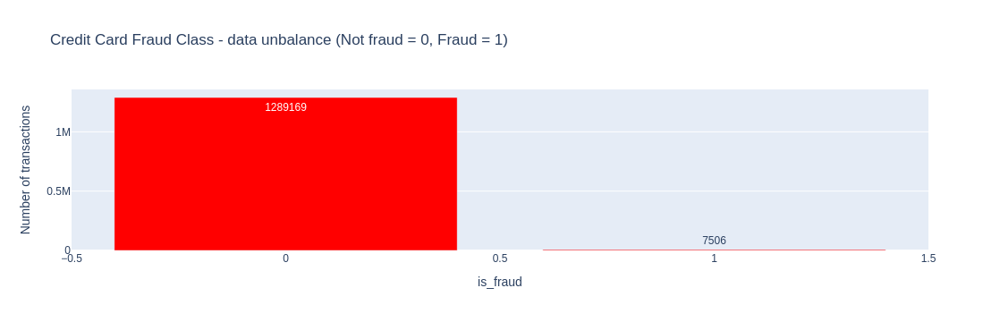

In [8]:
# plot bar chart for Not Fraud and Fraud entries, check data balance
temp = data_df["is_fraud"].value_counts() # in data_df['is_fraud'], get the number of entry of each value
df = pd.DataFrame({'is_fraud': temp.index,'values': temp.values})

trace = go.Bar(
    x = df['is_fraud'],y = df['values'],
    name="Credit Card Fraud Class - data unbalance (Not fraud = 0, Fraud = 1)",
    marker=dict(color="Red"),
    text=df['values']
)
data = [trace]
layout = dict(title = 'Credit Card Fraud Class - data unbalance (Not fraud = 0, Fraud = 1)',
          xaxis = dict(title = 'is_fraud', showticklabels=True),
          yaxis = dict(title = 'Number of transactions'),
          hovermode = 'closest',width=600
         )
fig = dict(data=data, layout=layout)
iplot(fig, filename='class') # use plotly

In [9]:
# convert date time format to the difference between the transactoin to first transcation, unit in second
df = data_df.copy()
df['trans_date_trans_time'] = pd.to_datetime(df['trans_date_trans_time'])
time_difference = df['trans_date_trans_time'] - df['trans_date_trans_time'].iloc[0]

df['time_difference_seconds'] = time_difference.dt.total_seconds()

df.iloc[78:85,-7:]

,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud,time_difference_seconds
78,1975-04-30,1240cd77c20744f96aa5e6a5cf9b1fcf,1325379482,42.889256,-71.888107,0,3464.0
79,1977-04-28,c7398ef8cebfefee82e590d473cf538b,1325379533,44.511030,-95.934394,0,3515.0
80,1954-05-25,673b35c970ef05a2acceb2af42f919d7,1325379565,40.237898,-79.894073,0,3547.0
81,1946-04-03,cfe0948d7b26c9fef58e59a9bf41d3e5,1325379619,39.308098,-81.698525,0,3601.0
82,1975-07-31,43204045928cb3449edc63078a75b48c,1325379648,39.335171,-104.102882,0,3630.0
83,1998-03-19,2686067ebeee0aa355a750faf309384e,1325379708,45.084808,-73.626071,0,3690.0
84,1974-12-23,1cb03ad950bab1ca74b02500644ec1ba,1325379736,40.773306,-92.821257,0,3718.0


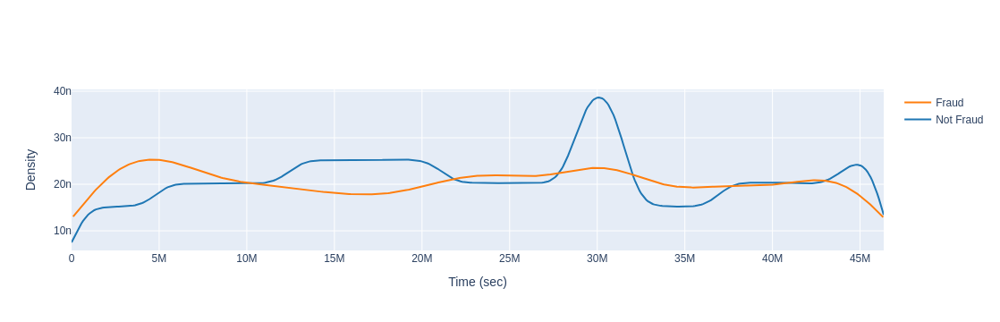

In [10]:
# plot density plot in second
class_0 = df.loc[df['is_fraud'] == 0]["time_difference_seconds"] # get rows with is_fraud == 0, but we only need the value under 'trans_date_trans_time'
class_1 = df.loc[df['is_fraud'] == 1]["time_difference_seconds"]

hist_data = [class_0, class_1]
group_labels = ['Not Fraud', 'Fraud']

fig = ff.create_distplot(hist_data, group_labels, show_hist=False, show_rug=False)
# fig['layout'].update(title='Credit Card Transactions Time Density Plot in secs', xaxis=dict(title='Time (sec)')) # time is sec between the transac & 1st transac
fig['layout'].update(xaxis=dict(title='Time (sec)'), yaxis=dict(title='Density')) 
iplot(fig, filename='dist_only') # use plotly

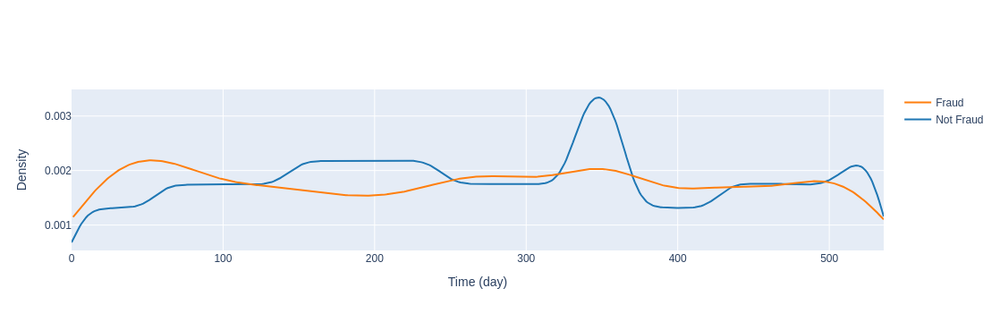

In [11]:
# plot density plot in days
df['hour'] = df['time_difference_seconds'].apply(lambda x: np.floor(x / 3600)) # data_df applied lambda function for np flooring for division of 3600 to hours 
df['day'] = df['hour'].apply(lambda x: np.floor(x / 24)) # data_df applied lambda function for np flooring for to convert hour to day

class_0 = df.loc[df['is_fraud'] == 0]['day'] # get rows with is_fraud == 0, but we only need the value under 'trans_date_trans_time'
class_1 = df.loc[df['is_fraud'] == 1]['day']

hist_data = [class_0, class_1]
group_labels = ['Not Fraud', 'Fraud']

fig = ff.create_distplot(hist_data, group_labels, show_hist=False, show_rug=False)
# fig['layout'].update(title='Credit Card Transactions Time Density Plot in days', xaxis=dict(title='Time (d)'))
fig['layout'].update(xaxis=dict(title='Time (day)'), yaxis=dict(title='Density'))
iplot(fig, filename='dist_only') # use plotly

In [12]:
# groupby data for hour and is_fraud
tmp = df.groupby(['hour', 'is_fraud'])['amt'].aggregate(['min', 'max', 'count', 'sum', 'mean', 'median', 'var']).reset_index() 
df_show = pd.DataFrame(tmp)
df_show.columns = ['Hour', 'is_fraud', 'Min', 'Max', 'Transactions', 'Sum', 'Mean', 'Median', 'Var'] # change the column of df_show
HTML(df_show.to_html(index=False)) # show df with html format and hide the indexes

Hour,is_fraud,Min,Max,Transactions,Sum,Mean,Median,Var
0.0,0,1.82,341.67,81,6803.91,83.998889,63.070,6.215336e+03
1.0,0,1.46,636.41,83,6396.72,77.068916,57.430,8.814218e+03
2.0,0,1.42,1055.47,77,5902.31,76.653377,56.340,1.587392e+04
3.0,0,1.10,909.66,67,6249.29,93.272985,68.230,1.933440e+04
4.0,0,1.75,494.44,73,5178.72,70.941370,56.980,6.189810e+03
5.0,0,1.13,494.16,79,5809.25,73.534810,56.310,5.639949e+03
6.0,0,1.34,1636.87,78,6668.21,85.489872,60.680,3.409965e+04
7.0,0,1.13,508.59,76,5292.91,69.643553,61.030,5.002379e+03
8.0,0,1.28,407.42,77,5622.97,73.025584,61.740,5.520525e+03
9.0,0,1.51,1047.52,87,7859.92,90.343908,62.920,2.305662e+04


~/anaconda3/envs/myenv1/lib/python3.11/site-packages/IPython/core/pylabtools.py:77: DeprecationWarning:

backend2gui is deprecated since IPython 8.24, backends are managed in matplotlib and can be externally registered.



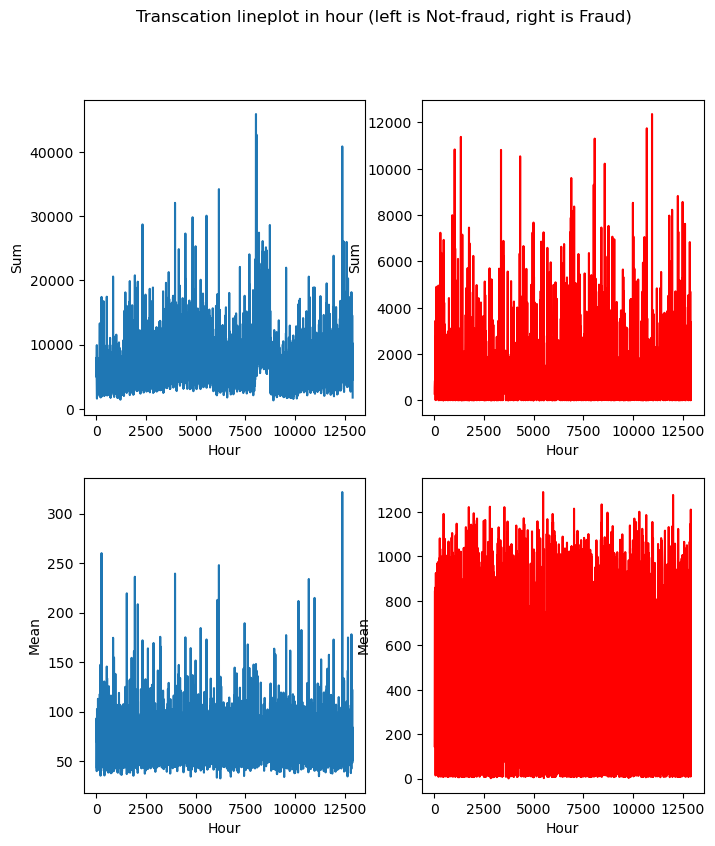

In [13]:
# use seaborn and matplotlib for plotting the hour and transaction amount sum plot.
fig, ax = plt.subplots(2, 2, figsize=(8,9))
s = sns.lineplot(ax = ax[0,0], x="Hour", y="Sum", data=df_show.loc[df_show.is_fraud==0]) # for Not-fraud data
s = sns.lineplot(ax = ax[0,1], x="Hour", y="Sum", data=df_show.loc[df_show.is_fraud==1], color="red") # for Fruad data

# use seaborn and matplotlib for plotting the hour and transaction mean plot.
s = sns.lineplot(ax = ax[1,0], x="Hour", y="Mean", data=df_show.loc[df_show.is_fraud==0]) # for Not-fraud data
s = sns.lineplot(ax = ax[1,1], x="Hour", y="Mean", data=df_show.loc[df_show.is_fraud==1], color="red") # for Fruad data
plt.suptitle("Transcation lineplot in hour (left is Not-fraud, right is Fraud)")
plt.show();

In [14]:
tmp = df.groupby(['day', 'is_fraud'])['amt'].aggregate(['min', 'max', 'count', 'sum', 'mean', 'median', 'var']).reset_index() 
df_show = pd.DataFrame(tmp)
df_show.columns = ['Day', 'is_fraud', 'Min', 'Max', 'Transactions', 'Sum', 'Mean', 'Median', 'Var'] # change the column of df_show
HTML(df_show.to_html(index=False)) # show df with html format and hide the indexes

Day,is_fraud,Min,Max,Transactions,Sum,Mean,Median,Var
0.0,0,1.03,3178.51,2414,156487.09,64.824809,45.240,13102.242347
1.0,0,1.03,1031.92,1112,68215.53,61.344901,45.810,6376.576282
1.0,1,7.03,844.80,7,2540.36,362.908571,276.310,122583.968914
2.0,0,1.07,1287.18,1223,79679.40,65.150777,48.290,8347.346836
2.0,1,4.50,1254.27,12,6804.78,567.065000,522.275,170756.095682
3.0,0,1.03,2753.89,1461,104914.63,71.810151,52.660,18839.945134
3.0,1,14.37,1099.99,13,7521.76,578.596923,722.180,173847.077223
4.0,0,1.02,1067.73,1396,90340.35,64.713718,48.885,7125.135158
4.0,1,4.58,1177.79,13,7155.78,550.444615,730.780,158860.418510
5.0,0,1.01,1101.55,2027,134051.04,66.132728,48.250,8077.140309


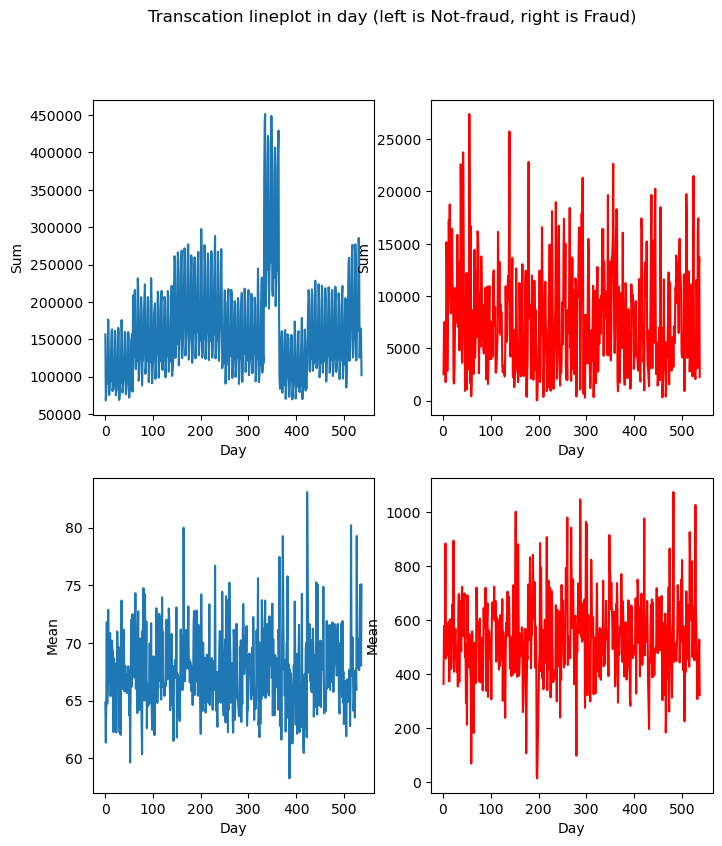

In [15]:
# use seaborn and matplotlib for plotting the day and transaction amount sum plot.
fig, ax = plt.subplots(2, 2, figsize=(8,9))
s = sns.lineplot(ax = ax[0,0], x="Day", y="Sum", data=df_show.loc[df_show.is_fraud==0]) # for Not-fraud data
s = sns.lineplot(ax = ax[0,1], x="Day", y="Sum", data=df_show.loc[df_show.is_fraud==1], color="red") # for Fruad data

# use seaborn and matplotlib for plotting the hour and transaction mean plot.
s = sns.lineplot(ax = ax[1,0], x="Day", y="Mean", data=df_show.loc[df_show.is_fraud==0]) # for Not-fraud data
s = sns.lineplot(ax = ax[1,1], x="Day", y="Mean", data=df_show.loc[df_show.is_fraud==1], color="red") # for Fruad data
plt.suptitle("Transcation lineplot in day (left is Not-fraud, right is Fraud)")
plt.show();

 is_fraud  Min      Max  Transactions No.         Sum       Mean  Median      Variance      Q25     Q50     Q75
        0 1.00 28948.90           1289169 87234340.29  67.667110  47.280  23718.454992   9.6100  47.280  82.540
        1 1.06  1376.04              7506  3988088.61 531.320092 396.505 152537.168064 245.6625 396.505 900.875


Amount box plot:


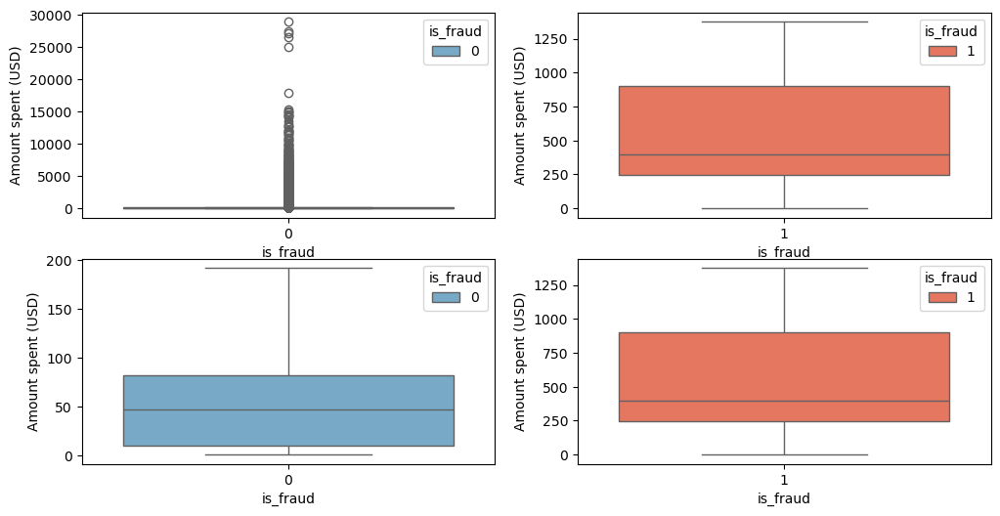

In [16]:
# get the 25, 50 and 75% quartile, then box plot of Not-fraud and Fruad amount
df_amount = data_df.groupby(['is_fraud'])['amt']
q_25 = df_amount.quantile(0.25).to_numpy()
q_50 = df_amount.quantile(0.5).to_numpy()
q_75 = df_amount.quantile(0.75).to_numpy()

tmp = df_amount.aggregate(['min', 'max', 'count', 'sum', 'mean', 'median', 'var']).reset_index() # aggregate cannot get quartiles
df = pd.DataFrame(tmp)
df.columns = ['is_fraud', 'Min', 'Max', 'Transactions No.', 'Sum', 'Mean', 'Median', 'Variance'] # change the column of df
df = df.assign(Q25=q_25, Q50=q_50, Q75=q_75) # add our obtained quartiles in the last rows
print(df.to_string(index=False))
print("\n\nAmount box plot:")

df_0 = data_df.loc[data_df.is_fraud==0]
df_1 = data_df.loc[data_df.is_fraud==1]

fig, ax = plt.subplots(nrows=2, ncols=2, figsize=(12,6))
s = sns.boxplot(ax = ax[0,0], x="is_fraud", y="amt", hue="is_fraud",data=df_0, palette="Blues",showfliers=True) # plot Not-Fraud
s.set_ylabel("Amount spent (USD)")
s = sns.boxplot(ax = ax[0,1], x="is_fraud", y="amt", hue="is_fraud",data=df_1, palette="Reds",showfliers=True) # plot Fraud
s.set_ylabel("Amount spent (USD)")
s = sns.boxplot(ax = ax[1,0], x="is_fraud", y="amt", hue="is_fraud",data=df_0, palette="Blues",showfliers=False) # hide Not-Fraud outliers
s.set_ylabel("Amount spent (USD)")
s = sns.boxplot(ax = ax[1,1], x="is_fraud", y="amt", hue="is_fraud",data=df_1, palette="Reds",showfliers=False) # hide Fraud outliers
s.set_ylabel("Amount spent (USD)")

plt.show();

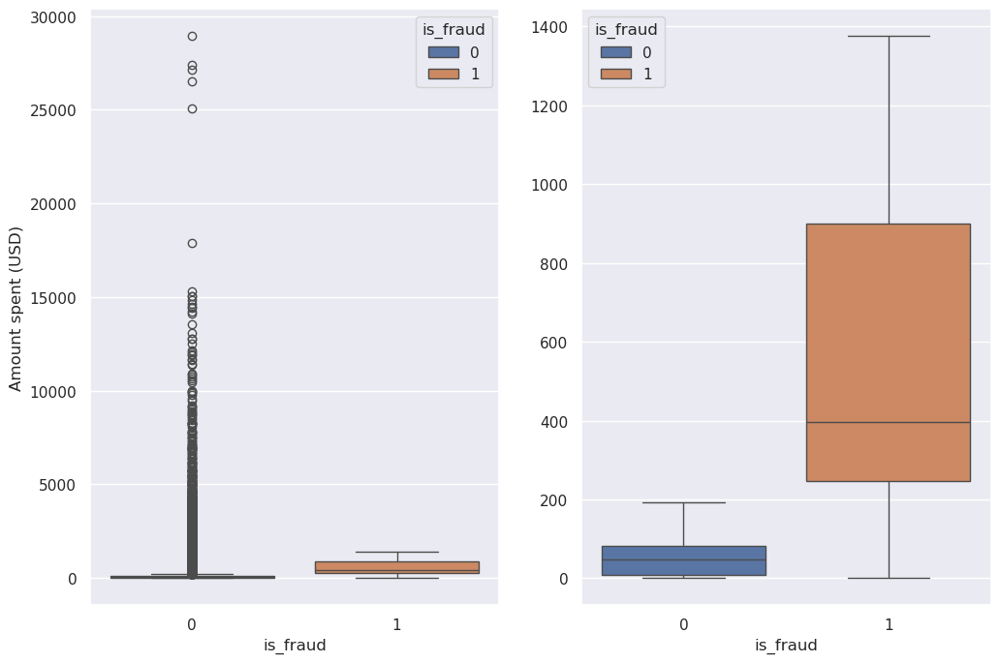

In [61]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(12,8))
sns.set_style("darkgrid")
s = sns.boxplot(ax = ax[0], x="is_fraud", y="amt", hue="is_fraud", data=data_df, showfliers=True) # plot Not-Fraud
s.set_ylabel("Amount spent (USD)")
s = sns.boxplot(ax = ax[1], x="is_fraud", y="amt", hue="is_fraud", data=data_df, showfliers=False) # plot Fraud
s.set_ylabel("")

plt.show();

number of variables: 2 x number of fraud transaction: 7506


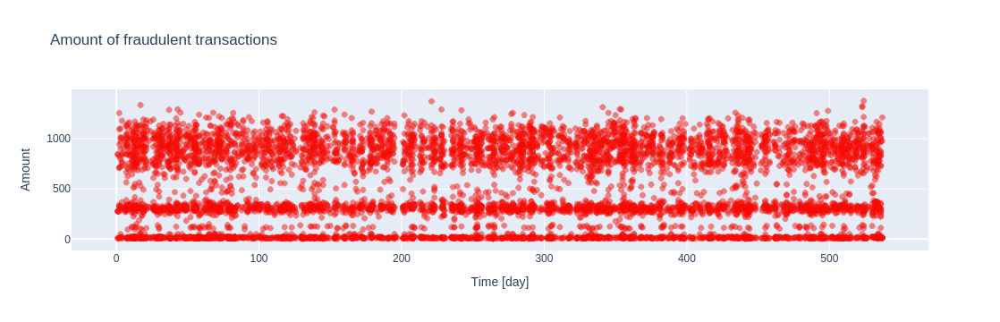

In [18]:
# get scatter plot of fraud data, time vs transaction amount of money
fraud = data_df.loc[data_df['is_fraud'] == 1]

fraud['trans_date_trans_time'] = pd.to_datetime(fraud['trans_date_trans_time'])
time_difference = fraud['trans_date_trans_time'] - pd.to_datetime(data_df['trans_date_trans_time'][0])

fraud['time_difference_seconds'] = time_difference.dt.total_seconds()
fraud['hour'] = fraud['time_difference_seconds'].apply(lambda x: np.floor(x / 3600)) # convert to hour
fraud['day'] = fraud['hour'].apply(lambda x: np.floor(x / 24)) # convert to day

df = pd.concat([fraud['amt'],fraud['day']], axis=1).transpose()
display(HTML(df.to_html(index=True,header=True)))
print("number of variables:", df.shape[0], "x number of fraud transaction:",df.shape[1])

trace = go.Scatter(
    x = fraud['day'],y = fraud['amt'],
    name="Amount",
     marker=dict(
                color='rgb(238,23,11)',
                line=dict(
                    color='red',
                    width=1),
                opacity=0.5,
            ),
    text= fraud['amt'],
    mode = "markers"
)
data = [trace]
layout = dict(title = 'Amount of fraudulent transactions',
          xaxis = dict(title = 'Time [day]', showticklabels=True), 
          yaxis = dict(title = 'Amount'),
          hovermode='closest'
         )
fig = dict(data=data, layout=layout)
iplot(fig, filename='fraud-amount')

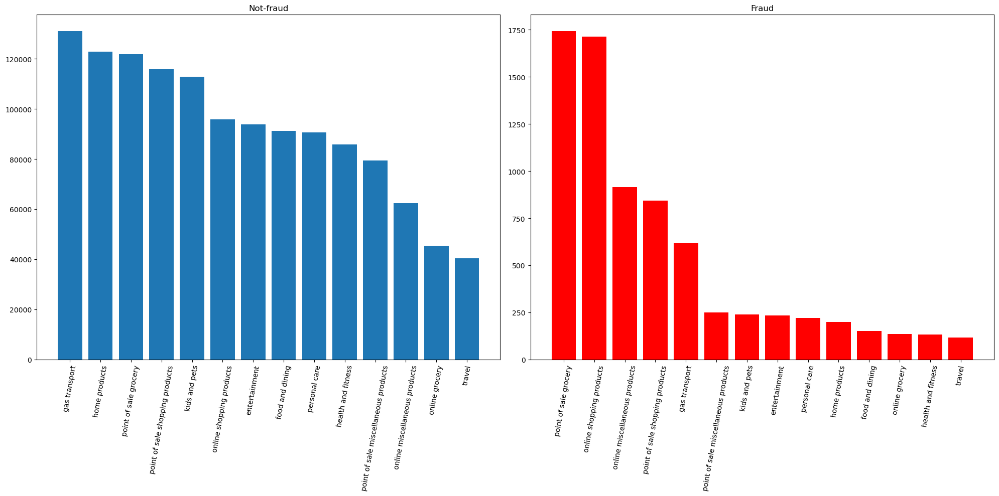

In [19]:
# Visualise value counts of column 'category'
df_notFraud = data_df.loc[data_df['is_fraud'] == 0] # define df for not-fraud
df_Fraud = data_df.loc[data_df['is_fraud'] == 1] # define df for fraud


notFraud_cat = dict(df_notFraud['category'].value_counts())
df_notFraud_cat = pd.DataFrame({'category': list(notFraud_cat.keys()), 'not-fraud': list(notFraud_cat.values())})
# display(HTML(df_notFraud_cat.to_html(index=False,header=True)))

Fraud_cat = dict(df_Fraud['category'].value_counts())
df_Fraud_cat = pd.DataFrame({'category': list(Fraud_cat.keys()), 'fraud': list(Fraud_cat.values())})
# display(HTML(df_Fraud_cat.to_html(index=False,header=True)))


fig, axes = plt.subplots(1, 2, figsize=(20, 10))
axes[0].bar(df_notFraud_cat.iloc[:, 0], df_notFraud_cat.iloc[:, 1])
axes[0].set_title('Not-fraud')
axes[0].tick_params(axis='x', labelrotation=80)
axes[1].bar(df_Fraud_cat.iloc[:, 0], df_Fraud_cat.iloc[:, 1], color="red")
axes[1].set_title('Fraud')
axes[1].tick_params(axis='x', labelrotation=80)
plt.tight_layout()
plt.show()

Convert data column data of birth ('dob') to card holder's age:
0          30
1          40
2          56
3          51
4          32
           ..
1296670    58
1296671    40
1296672    52
1296673    39
1296674    24
Length: 1296675, dtype: int64
<class 'pandas.core.series.Series'>
===========================================Not-fraud age================================================================


age,not-fraud
13,80
14,3929
15,6048
16,3063
17,2318
18,5574
19,13606
20,15767
21,19497
22,20070


/tmp/ipykernel_3058192/2713089493.py:38: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
age_group,13-15,16-20,21-25,26-30,31-35,36-40,41-45,46-50,51-55,56-60,61-65,66-70,71-75,76-80,81-85,86-90,91-95
sum,10057,40328,93782,125062,173493,113255,152439,144631,96609,86802,75588,52267,37217,30670,22311,20217,14441


===========================================Fraud age===============================================================


age,fraud
14,12
15,27
16,21
17,58
18,19
19,86
20,72
21,151
22,100
23,113


/tmp/ipykernel_3058192/2713089493.py:53: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
age_group,13-15,16-20,21-25,26-30,31-35,36-40,41-45,46-50,51-55,56-60,61-65,66-70,71-75,76-80,81-85,86-90,91-95
sum,39,256,600,677,740,507,639,781,664,730,507,330,220,329,193,170,124


===========================================Graph================================================================


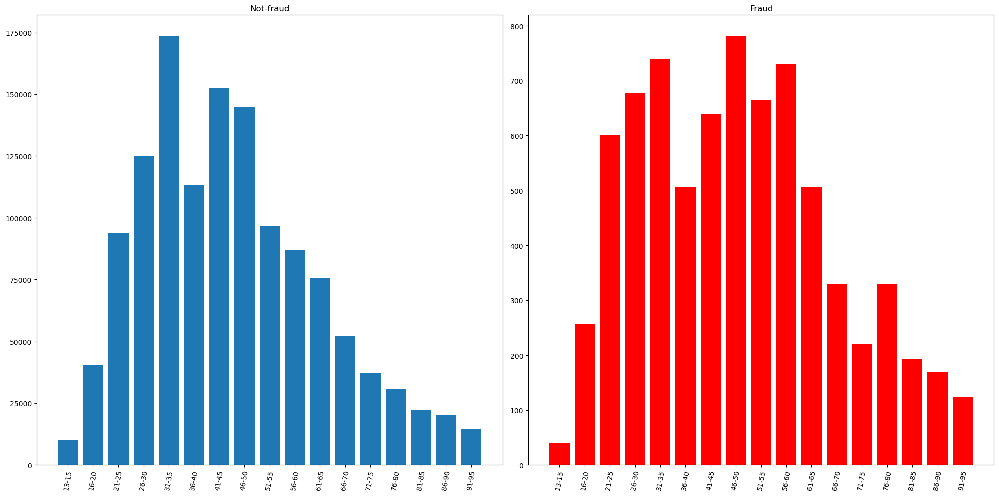

In [20]:
# Visualise value counts of column 'age'


# Convert the DataFrame from date of birth ('dob') to age ('age')
date_se = pd.to_datetime(data_df['trans_date_trans_time'])
dob_se = pd.to_datetime(data_df['dob'])

day_diff = (date_se - dob_se)

time_diff = day_diff.astype('int64')

age = (time_diff/((10**6) * 60 * 60 * 24 * 365.25 *1000)).astype('int64') # convert microsecond to year, times 1000 at last to remove 000
print("Convert data column data of birth ('dob') to card holder's age:")
print(age)
print(type(age))

df = data_df.copy()
df['dob'] = age
df.rename({'dob': 'age'}, axis=1, inplace=True)

print("===========================================Not-fraud age================================================================")

# define the cutting edges and the age group for our 'age' column
bins = [12, 15, 20, 25, 30, 35, 40, 45, 50, 55, 60, 65, 70, 75, 80, 85, 90, 95] # define the bins to cut the age
age_grp = ['13-15', '16-20', '21-25', '26-30', '31-35', '36-40', '41-45', '46-50', 
           '51-55', '56-60', '61-65', '66-70', '71-75', '76-80', '81-85', '86-90', "91-95"] # define our age group

# data process of column 'age' for not-fraud
df_notFraud = df.loc[df['is_fraud'] == 0] # define df for not-fraud

notFraud_age = dict(df_notFraud['age'].value_counts())
df_notFraud_age = pd.DataFrame({'age': list(notFraud_age.keys()), 'not-fraud': list(notFraud_age.values())})
df_notFraud_age = df_notFraud_age.sort_values(by=['age'])
display(HTML(df_notFraud_age.to_html(index=False,header=True)))

df_notFraud_age['age_group'] = pd.cut(df_notFraud_age['age'], bins=bins, labels=age_grp, right=True)
# display(HTML(df_notFraud_age.to_html(index=False,header=True)))
df_notFraud_agegrp = df_notFraud_age.groupby(['age_group'])['not-fraud'].aggregate(['sum']).reset_index()
display(HTML(df_notFraud_agegrp.transpose().to_html(index=True,header=True)))

print("===========================================Fraud age===============================================================")
 
# data process of column 'age' for fraud
df_Fraud = df.loc[df['is_fraud'] == 1] # define df for fraud

Fraud_age = dict(df_Fraud['age'].value_counts())
df_Fraud_age = pd.DataFrame({'age': list(Fraud_age.keys()), 'fraud': list(Fraud_age.values())})
df_Fraud_age = df_Fraud_age.sort_values(by=['age'])
display(HTML(df_Fraud_age.to_html(index=False,header=True)))

df_Fraud_age['age_group'] = pd.cut(df_Fraud_age['age'], bins=bins, labels=age_grp, right=True)
# display(HTML(df_Fraud_age.to_html(index=False,header=True)))
df_Fraud_agegrp = df_Fraud_age.groupby(['age_group'])['fraud'].aggregate(['sum']).reset_index()
display(HTML(df_Fraud_agegrp.transpose().to_html(index=True,header=True)))

print("===========================================Graph================================================================")

# plot graphs for age group for both not-fraud and fraud by subplot
fig, axes = plt.subplots(1, 2, figsize=(20, 10))
axes[0].bar(df_notFraud_agegrp.iloc[:, 0], df_notFraud_agegrp.iloc[:, 1])
axes[0].set_title('Not-fraud')
axes[0].tick_params(axis='x', labelrotation=80)
axes[1].bar(df_Fraud_agegrp.iloc[:, 0], df_Fraud_agegrp.iloc[:, 1], color="red")
axes[1].set_title('Fraud')
axes[1].tick_params(axis='x', labelrotation=80)
plt.tight_layout()
plt.show()

#### Cross features

In [21]:
# data_df = original_df.copy()

df_nonFraud = data_df.loc[data_df['is_fraud']==0]
df_Fraud = data_df.loc[data_df['is_fraud']==1]

##### category vs amt

{'entertainment': 233, 'food and dining': 151, 'gas transport': 618, 'health and fitness': 133, 'home products': 198, 'kids and pets': 239, 'online grocery': 134, 'online miscellaneous products': 915, 'online shopping products': 1713, 'personal care': 220, 'point of sale grocery': 1743, 'point of sale miscellaneous products': 250, 'point of sale shopping products': 843, 'travel': 116}


category,total_counts,fraud_counts,fraud_perc
home products,94014,233,0.247835
kids and pets,40507,116,0.286370
entertainment,91461,151,0.165098
food and dining,131659,618,0.469394
health and fitness,85879,133,0.154869
personal care,123115,198,0.160825
gas transport,113035,239,0.211439
travel,45452,134,0.294817
online grocery,63287,915,1.445795
point of sale grocery,97543,1713,1.756149


category                              is_fraud
entertainment                         0            93781
                                      1              233
food and dining                       0            91310
                                      1              151
gas transport                         0           131041
                                      1              618
health and fitness                    0            85746
                                      1              133
home products                         0           122917
                                      1              198
kids and pets                         0           112796
                                      1              239
online grocery                        0            45318
                                      1              134
online miscellaneous products         0            62372
                                      1              915
online shopping products              0  

/tmp/ipykernel_3058192/183697549.py:44: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




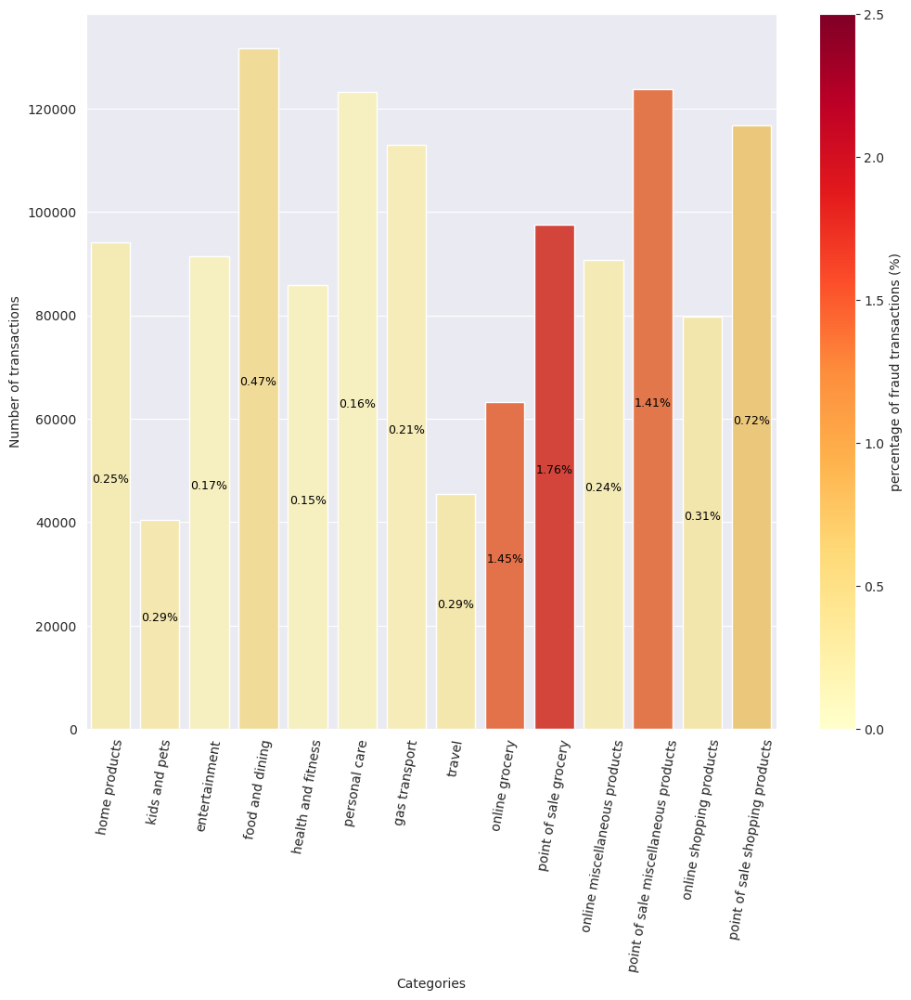

In [22]:
df_cat = data_df.copy()

category_list = ["home", "kids_pets", "entertainment", "food_dining", "health_fitness", "personal_care", "gas_transport", "travel", 
                 "grocery_net", "grocery_pos", "misc_net", "misc_pos", "shopping_net", "shopping_pos"] # order following the encoding order
category_list_edited = ["home products", "kids and pets", "entertainment", "food and dining", 
                        "health and fitness", "personal care", "gas transport", "travel", 
                 "online grocery", "point of sale grocery", "online miscellaneous products", "point of sale miscellaneous products", 
                 "online shopping products", "point of sale shopping products"] # order following the encoding order

df_cat_fraud_perc = pd.DataFrame({'total_counts' : df_cat.groupby(['category']).size()}).reset_index()

cat_fraud_dict = {}
for category in df_cat_fraud_perc['category']:
    df = df_cat.loc[df_cat['category']==category]
    cat_nonFraud, cat_Fraud = df['is_fraud'].value_counts().values
    cat_fraud_dict[category] = cat_Fraud

print(cat_fraud_dict)

df_cat_fraud_perc['fraud_counts'] = cat_fraud_dict.values()
df_cat_fraud_perc['fraud_perc'] = (np.array(list(cat_fraud_dict.values()))/df_cat_fraud_perc['total_counts'])*100

df_cat_fraud_perc["category"] = pd.Categorical(df_cat_fraud_perc["category"], category_list)
df_cat_fraud_perc = df_cat_fraud_perc.sort_values("category")

cat_enc_list = []

df_cat_fraud_perc['category'] = category_list_edited

display(HTML(df_cat_fraud_perc.to_html(index=False)))


print(df_cat.groupby(['category', 'is_fraud']).size())

norm = plt.Normalize(0, 2.5)
sm = plt.cm.ScalarMappable(cmap="YlOrRd", norm=norm)

plt.figure(figsize=(12, 10))

sns.set_style("darkgrid")

colors = list(plt.cm.YlOrRd(norm(df_cat_fraud_perc['fraud_perc'])))

bar = sns.barplot(x='category', y='total_counts', data=df_cat_fraud_perc, palette=colors)

cbar = plt.colorbar(sm, ax=bar)
cbar.set_label('percentage of fraud transactions (%)')

i = 0
for p in bar.patches: # add annotation of percentage
    height = p.get_height()
    fraud_percentage = df_cat_fraud_perc['fraud_perc'].iloc[i]
    bar.annotate(f'{fraud_percentage:.2f}%', 
                 (p.get_x() + p.get_width() / 2., height / 2), 
                 ha='center', va='center', 
                 fontsize=9, 
                 color='black', 
                 xytext=(0, 5),
                 textcoords='offset points')
    i = i+1

bar.tick_params(axis='x', labelrotation=80)
bar.set_ylabel('Number of transactions')
bar.set_xlabel('Categories')

plt.show()

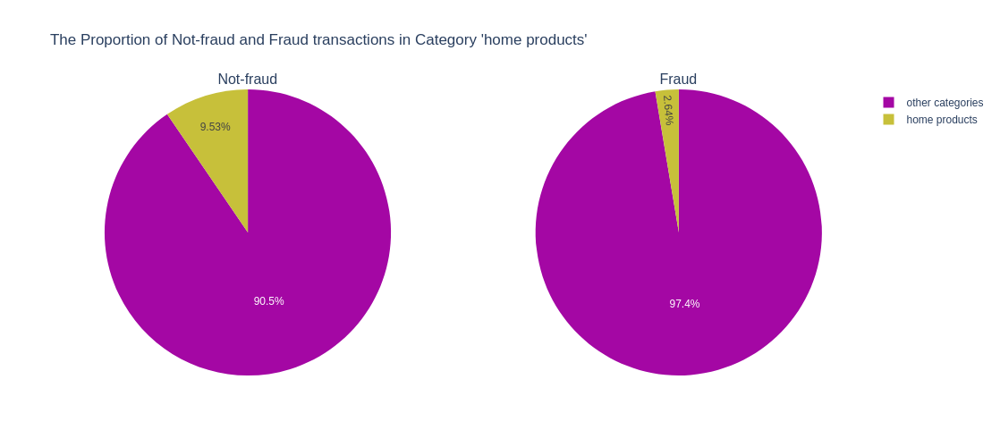

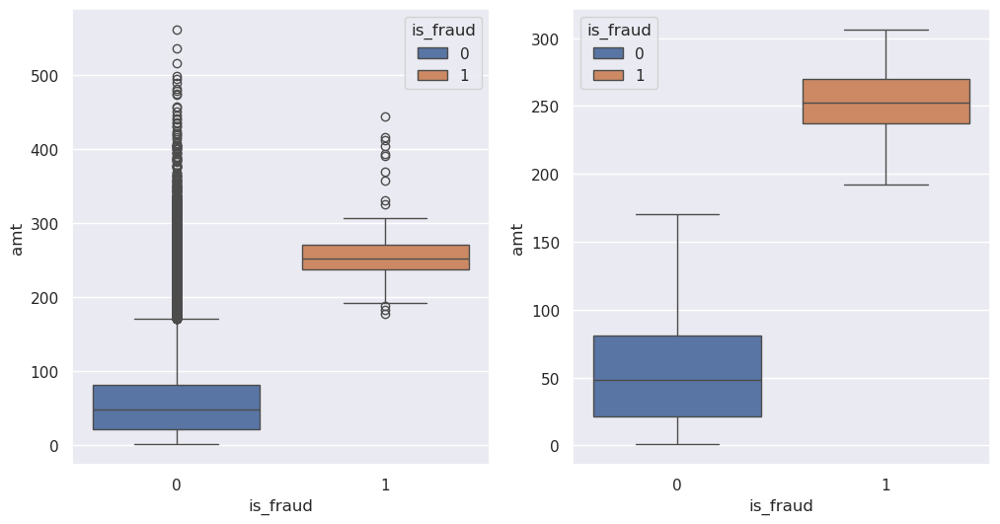

In [51]:
# home
selected_cat = "home products"

df = data_df.loc[data_df['category']==selected_cat]

nonFraud_cat = df_nonFraud.loc[df_nonFraud['category']==selected_cat].shape[0]
nonFraud_else = df_nonFraud.shape[0] - nonFraud_cat
Fraud_cat = df_Fraud.loc[df_Fraud['category']==selected_cat].shape[0]
Fraud_else = df_Fraud.shape[0] - Fraud_cat

cat_label = [selected_cat, "other categories"]
nonFraud_counts = [nonFraud_cat, nonFraud_else]
fraud_counts = [Fraud_cat, Fraud_else]

fig = make_subplots(1, 2, specs=[[{'type': 'domain'}, {'type': 'domain'}]],
                    subplot_titles=['Not-fraud', 'Fraud'])

fig.add_trace(go.Pie(labels=cat_label, values=nonFraud_counts,
                     name=f"{selected_cat} Not-fraud", marker=dict(colors=['#c7c03a', '#a407a4'])), 1, 1)
fig.add_trace(go.Pie(labels=cat_label, values=fraud_counts,
                     name=f"{selected_cat} Fraud", marker=dict(colors=['#c7c03a', '#a407a4'])), 1, 2)

fig.update_layout(
    title_text=f"The Proportion of Not-fraud and Fraud transactions in Category '{selected_cat}'",
    showlegend=True,  # Hide the legend if not needed
    uniformtext_minsize=12,  # Make sure text is visible
    uniformtext_mode='hide',  # Prevent overlapping text
    height=500,  # Set height to control overall plot size
    width=1000,   # Set width to ensure equal pie size
)

fig.show()

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(12,6))
s = sns.boxplot(ax=ax[0], x="is_fraud", y="amt", hue="is_fraud", data=df, showfliers=True)  # with outlier
s = sns.boxplot(ax=ax[1], x="is_fraud", y="amt", hue="is_fraud", data=df, showfliers=False) # without outlier
plt.show();

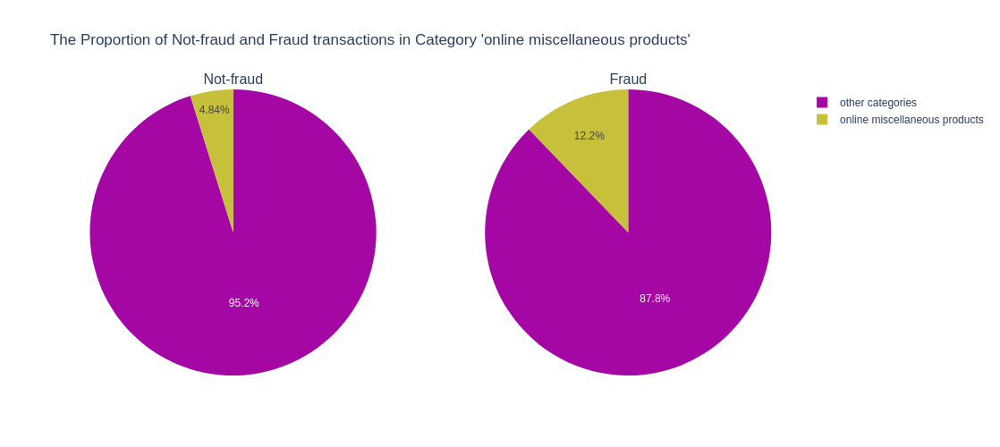

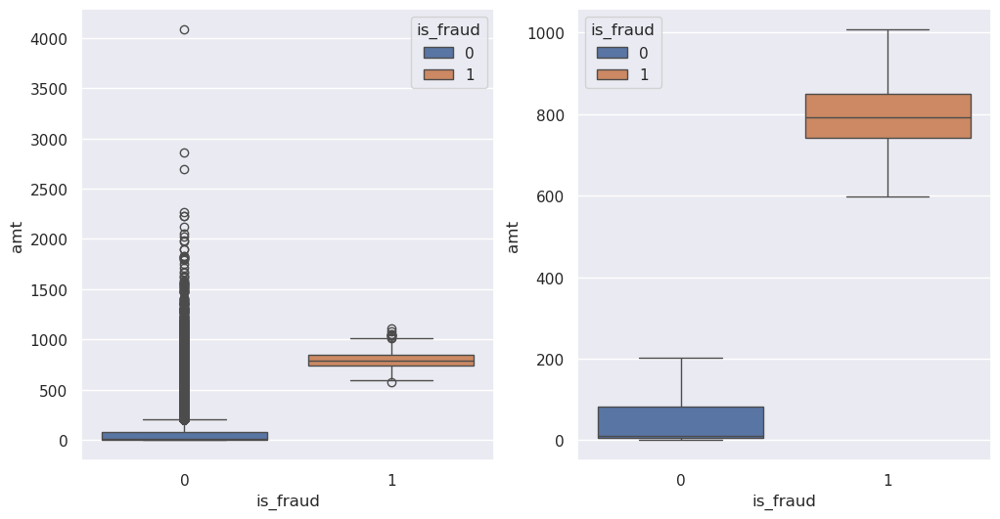

In [52]:
# misc_net
selected_cat = "online miscellaneous products"

df = data_df.loc[data_df['category']==selected_cat]

nonFraud_cat = df_nonFraud.loc[df_nonFraud['category']==selected_cat].shape[0]
nonFraud_else = df_nonFraud.shape[0] - nonFraud_cat
Fraud_cat = df_Fraud.loc[df_Fraud['category']==selected_cat].shape[0]
Fraud_else = df_Fraud.shape[0] - Fraud_cat

cat_label = [selected_cat, "other categories"]
nonFraud_counts = [nonFraud_cat, nonFraud_else]
fraud_counts = [Fraud_cat, Fraud_else]

fig = make_subplots(1, 2, specs=[[{'type': 'domain'}, {'type': 'domain'}]],
                    subplot_titles=['Not-fraud', 'Fraud'])

fig.add_trace(go.Pie(labels=cat_label, values=nonFraud_counts,
                     name=f"{selected_cat} Not-fraud", marker=dict(colors=['#c7c03a', '#a407a4'])), 1, 1)
fig.add_trace(go.Pie(labels=cat_label, values=fraud_counts,
                     name=f"{selected_cat} Fraud", marker=dict(colors=['#c7c03a', '#a407a4'])), 1, 2)

fig.update_layout(
    title_text=f"The Proportion of Not-fraud and Fraud transactions in Category '{selected_cat}'",
    showlegend=True,  # Hide the legend if not needed
    uniformtext_minsize=12,  # Make sure text is visible
    uniformtext_mode='hide',  # Prevent overlapping text
    height=500,  # Set height to control overall plot size
    width=1000,   # Set width to ensure equal pie size
)

fig.show()

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(12,6))
s = sns.boxplot(ax=ax[0], x="is_fraud", y="amt", hue="is_fraud", data=df, showfliers=True)  # with outlier
s = sns.boxplot(ax=ax[1], x="is_fraud", y="amt", hue="is_fraud", data=df, showfliers=False) # without outlier
plt.show();

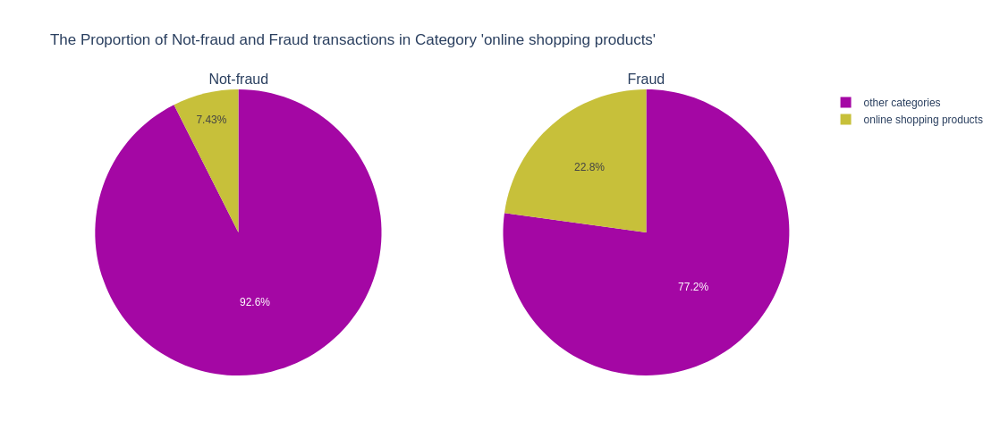

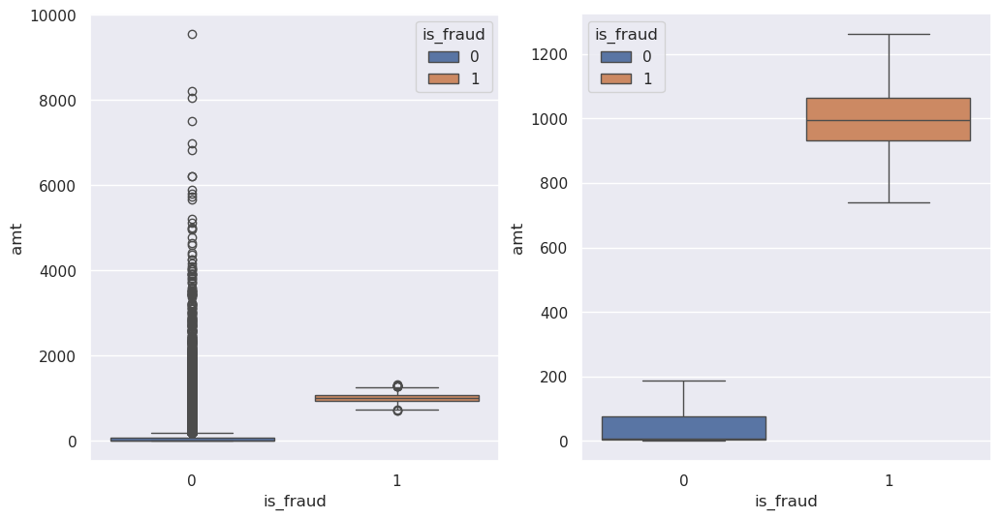

In [53]:
# shopping_net
selected_cat = "online shopping products"

df = data_df.loc[data_df['category']==selected_cat]

nonFraud_cat = df_nonFraud.loc[df_nonFraud['category']==selected_cat].shape[0]
nonFraud_else = df_nonFraud.shape[0] - nonFraud_cat
Fraud_cat = df_Fraud.loc[df_Fraud['category']==selected_cat].shape[0]
Fraud_else = df_Fraud.shape[0] - Fraud_cat

cat_label = [selected_cat, "other categories"]
nonFraud_counts = [nonFraud_cat, nonFraud_else]
fraud_counts = [Fraud_cat, Fraud_else]

fig = make_subplots(1, 2, specs=[[{'type': 'domain'}, {'type': 'domain'}]],
                    subplot_titles=['Not-fraud', 'Fraud'])

fig.add_trace(go.Pie(labels=cat_label, values=nonFraud_counts,
                     name=f"{selected_cat} Not-fraud", marker=dict(colors=['#c7c03a', '#a407a4'])), 1, 1)
fig.add_trace(go.Pie(labels=cat_label, values=fraud_counts,
                     name=f"{selected_cat} Fraud", marker=dict(colors=['#c7c03a', '#a407a4'])), 1, 2)

fig.update_layout(
    title_text=f"The Proportion of Not-fraud and Fraud transactions in Category '{selected_cat}'",
    showlegend=True,  # Hide the legend if not needed
    uniformtext_minsize=12,  # Make sure text is visible
    uniformtext_mode='hide',  # Prevent overlapping text
    height=500,  # Set height to control overall plot size
    width=1000,   # Set width to ensure equal pie size
)

fig.show()

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(12,6))
s = sns.boxplot(ax=ax[0], x="is_fraud", y="amt", hue="is_fraud", data=df, showfliers=True)  # with outlier
s = sns.boxplot(ax=ax[1], x="is_fraud", y="amt", hue="is_fraud", data=df, showfliers=False) # without outlier
plt.show();

##### age vs category vs amt

In [26]:
# Convert data from date of birth to age, classify into age_grp
df_age = data_df.copy()

date_se = pd.to_datetime(data_df['trans_date_trans_time'])
dob_se = pd.to_datetime(data_df['dob'])

day_diff = (date_se - dob_se)

time_diff = day_diff.astype('int64')

age = (time_diff/((10**6) * 60 * 60 * 24 * 365.25 *1000)).astype('int64') # convert microsecond to year, times 1000 at last to remove 000

df_age['dob'] = age
df_age.rename(columns = {'dob':'cardholder_age'}, inplace = True)

def classify_age(age):
    if age < 19:
        return "13-19"
    elif 20 <= age <= 29:
        return "20-29"
    elif 30 <= age <= 39:
        return "30-39"
    elif 40 <= age <= 49:
        return "40-49"
    elif 50 <= age <= 59:
        return "50-59"
    elif 60 <= age <= 69:
        return "60-69"
    elif 70 <= age <= 79:
        return "70-79"
    elif 80 <= age <= 89:
        return "80-89"
    else: # 90-95
        return "90-95"

df_age['age_grp'] = df_age['cardholder_age'].apply(classify_age)

is_fraud,age_grp,count,relative_perc
0,13-19,21012,1.629887
0,20-29,208004,16.134735
0,30-39,290016,22.496352
0,40-49,302951,23.499712
0,50-59,183559,14.238552
0,60-69,135641,10.521584
0,70-79,72257,5.604928
0,80-89,41934,3.252793
0,90-95,33795,2.621456
1,13-19,137,1.825207


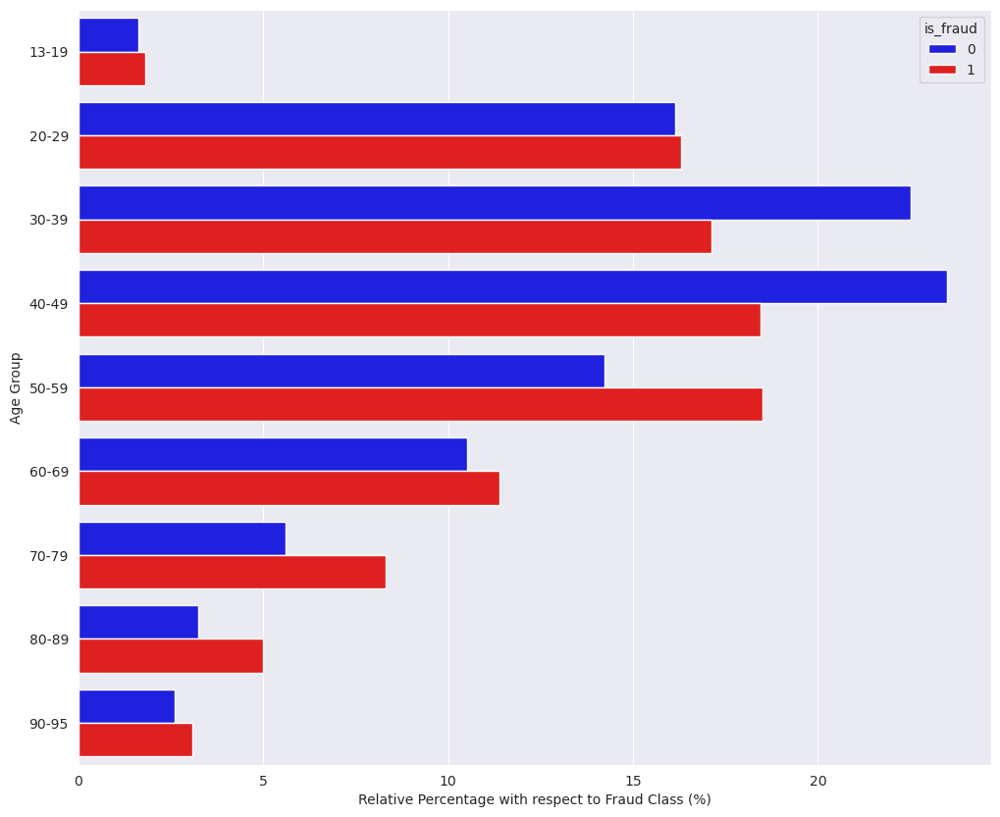

In [27]:
# Plot relative perc of age_grp, non-Fraud vs Fraud
df_age_fraud_perc = pd.DataFrame({'count' : df_age.groupby(['is_fraud', 'age_grp']).size()}).reset_index()

age_perc_nonFraud = []
for non_fraud in df_age_fraud_perc['count'][:9]:
    perc = (non_fraud / df_age_fraud_perc['count'][:9].sum())*100
    age_perc_nonFraud.append(perc)

age_perc_Fraud = []
for fraud in df_age_fraud_perc['count'][9:]:
    perc = (fraud / df_age_fraud_perc['count'][9:].sum())*100
    age_perc_Fraud.append(perc)

df_age_fraud_perc['relative_perc'] = age_perc_nonFraud + age_perc_Fraud

display(HTML(df_age_fraud_perc.to_html(index=False)))


plt.figure(figsize=(12, 10))

bar = sns.barplot(x='relative_perc',  y='age_grp', hue='is_fraud', palette=["blue", "red"], data=df_age_fraud_perc) 
bar.set_ylabel('Age Group', fontsize=10)
bar.set_xlabel('Relative Percentage with respect to Fraud Class (%)', fontsize=10)

plt.show()

{'13-19': 137, '20-29': 1223, '30-39': 1286, '40-49': 1385, '50-59': 1388, '60-69': 855, '70-79': 625, '80-89': 375, '90-95': 232}


age_grp,total_counts,fraud_counts,non_fraud_counts,fraud_perc
13-19,21149,137,21012,0.647785
20-29,209227,1223,208004,0.584533
30-39,291302,1286,290016,0.441466
40-49,304336,1385,302951,0.455089
50-59,184947,1388,183559,0.750485
60-69,136496,855,135641,0.626392
70-79,72882,625,72257,0.857551
80-89,42309,375,41934,0.886336
90-95,34027,232,33795,0.681812


/tmp/ipykernel_3058192/3642962883.py:28: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




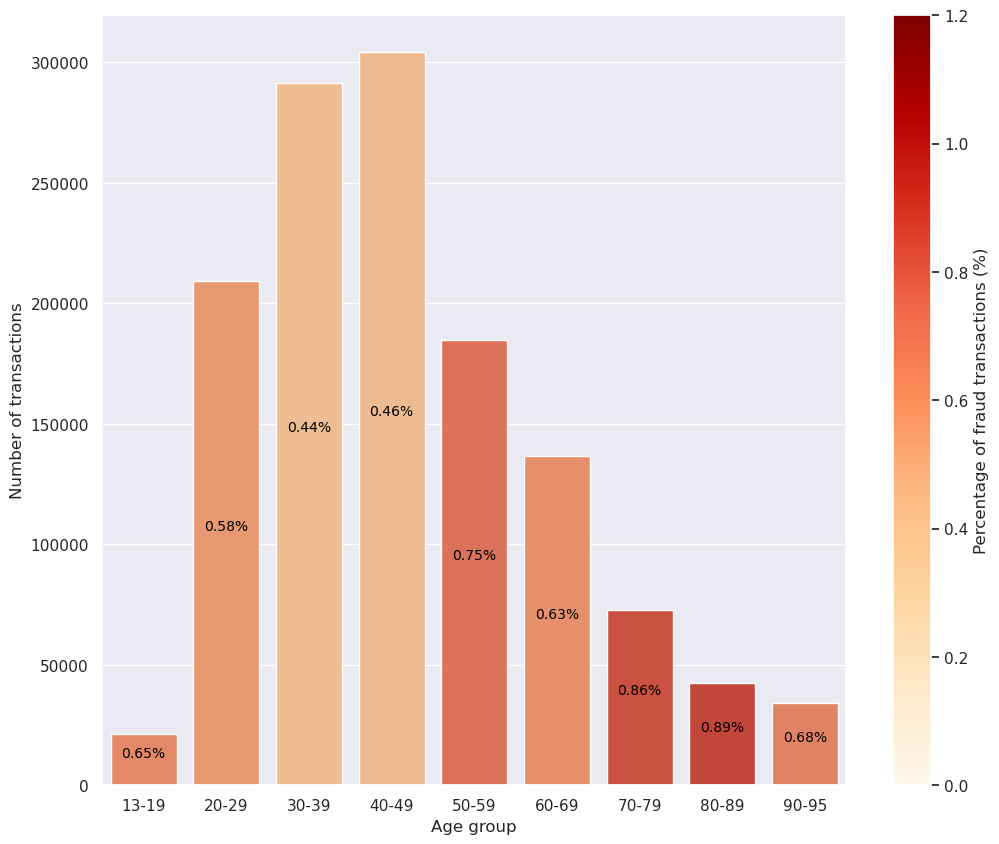

In [55]:
# Plot relative perc of age_grp, non-Fraud vs Fraud
df_age_fraud_perc = pd.DataFrame({'total_counts' : df_age.groupby(['age_grp']).size()}).reset_index()

age_fraud_dict = {}
for age_grp in df_age_fraud_perc['age_grp']:
    df = df_age.loc[df_age['age_grp']==age_grp]
    age_nonFraud, age_Fraud = df['is_fraud'].value_counts().values
    age_fraud_dict[age_grp] = age_Fraud

print(age_fraud_dict)

df_age_fraud_perc['fraud_counts'] = age_fraud_dict.values()
df_age_fraud_perc['non_fraud_counts'] = df_age_fraud_perc['total_counts'] - df_age_fraud_perc['fraud_counts']

df_age_fraud_perc['fraud_perc'] = (np.array(list(age_fraud_dict.values()))/df_age_fraud_perc['total_counts'])*100
df_age_fraud_perc['fraud_perc'] = df_age_fraud_perc['fraud_perc'].astype('float')

display(HTML(df_age_fraud_perc.to_html(index=False)))


norm = plt.Normalize(0, 1.2)
sm = plt.cm.ScalarMappable(cmap="OrRd", norm=norm)

plt.figure(figsize=(12, 10))
# colors = list(plt.cm.YlOrRd(norm(df_age_fraud_perc['fraud_perc'])))
colors = list(plt.cm.OrRd(norm(df_age_fraud_perc['fraud_perc'])))

bar = sns.barplot(x='age_grp', y='total_counts', data=df_age_fraud_perc, palette=colors)

cbar = plt.colorbar(sm, ax=bar)
cbar.set_label('Percentage of fraud transactions (%)')

bar.set_ylabel('Number of transactions')
bar.set_xlabel('Age group')

i = 0
for p in bar.patches: # add annotation of percentage
    height = p.get_height()
    fraud_percentage = df_age_fraud_perc['fraud_perc'].iloc[i]
    bar.annotate(f'{fraud_percentage:.2f}%', 
                 (p.get_x() + p.get_width() / 2., height / 2), 
                 ha='center', va='center', 
                 fontsize=10, 
                 color='black', 
                 xytext=(0, 5),
                 textcoords='offset points')
    i = i+1

plt.show()

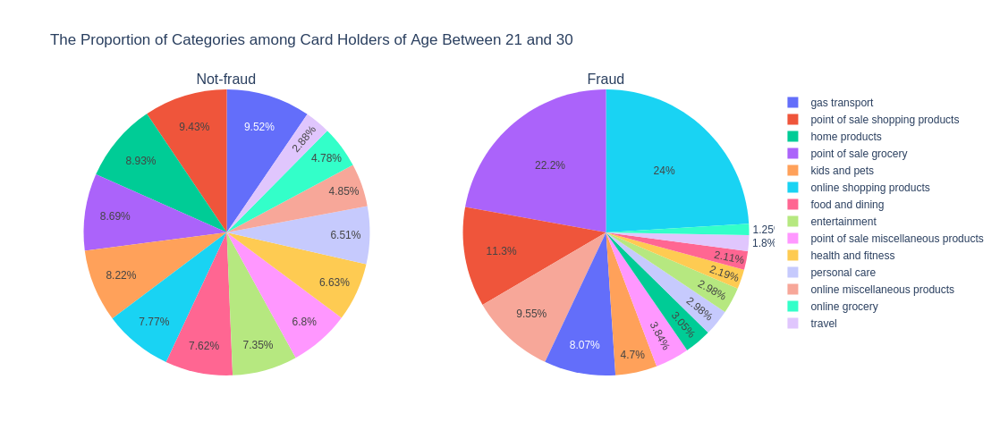

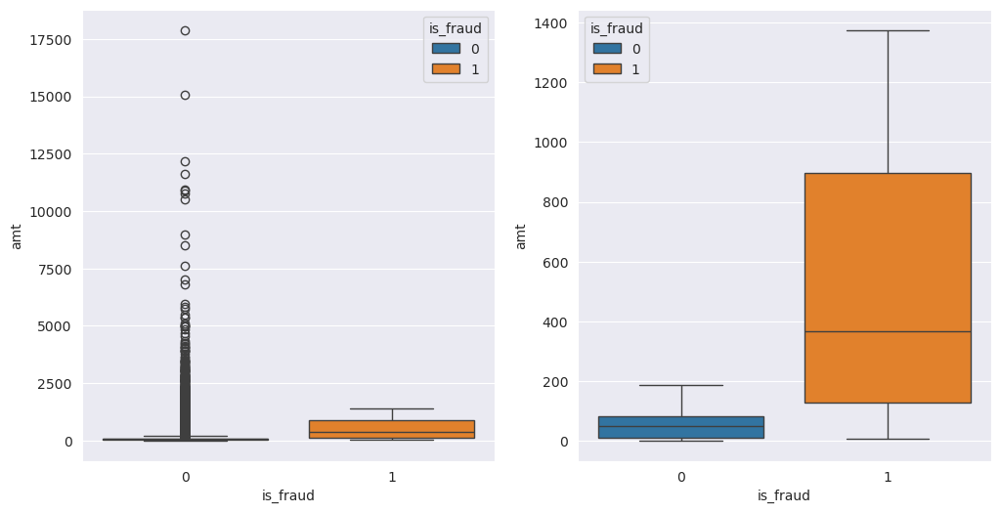

In [29]:
# age: 21-30
age_grp = [21, 30]

df = df_age.loc[(df_age['cardholder_age'] >= age_grp[0]) & (df_age['cardholder_age'] <= age_grp[1])]
df_age_nonFraud = df.loc[df['is_fraud']==0]
df_age_Fraud = df.loc[df['is_fraud']==1]

nonFraud_values = df_age_nonFraud['category'].value_counts().values
nonFraud_label = list(df_age_nonFraud['category'].value_counts().index)
Fraud_values = df_age_Fraud['category'].value_counts().values
Fraud_label = list(df_age_Fraud['category'].value_counts().index)

fig = make_subplots(1, 2, specs=[[{'type': 'domain'}, {'type': 'domain'}]],
                    subplot_titles=['Not-fraud', 'Fraud'])

fig.add_trace(go.Pie(labels=nonFraud_label, values=nonFraud_values,
                     name=f"Age of Card Holder Between {age_grp[0]} and {age_grp[1]}, Not-fraud",
                     # marker=dict(colors=['#c7c03a', '#a407a4'])), 
                    ),
              1, 1)
fig.add_trace(go.Pie(labels=Fraud_label, values=Fraud_values,
                     name=f"Age of Card Holder Between {age_grp[0]} and {age_grp[1]}, Fraud",
                     # marker=dict(colors=['#c7c03a', '#a407a4'])), 
                    ),
              1, 2)

fig.update_layout(
    title_text=f"The Proportion of Categories among Card Holders of Age Between {age_grp[0]} and {age_grp[1]}",
    showlegend=True,  # Hide the legend if not needed
    uniformtext_minsize=12,  # Make sure text is visible
    uniformtext_mode='hide',  # Prevent overlapping text
    height=500,  # Set height to control overall plot size
    width=1000,   # Set width to ensure equal pie size
)

fig.show()

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(12,6))
s = sns.boxplot(ax=ax[0], x="is_fraud", y="amt", hue="is_fraud", data=df, showfliers=True)  # with outlier
s = sns.boxplot(ax=ax[1], x="is_fraud", y="amt", hue="is_fraud", data=df, showfliers=False) # without outlier
plt.show();

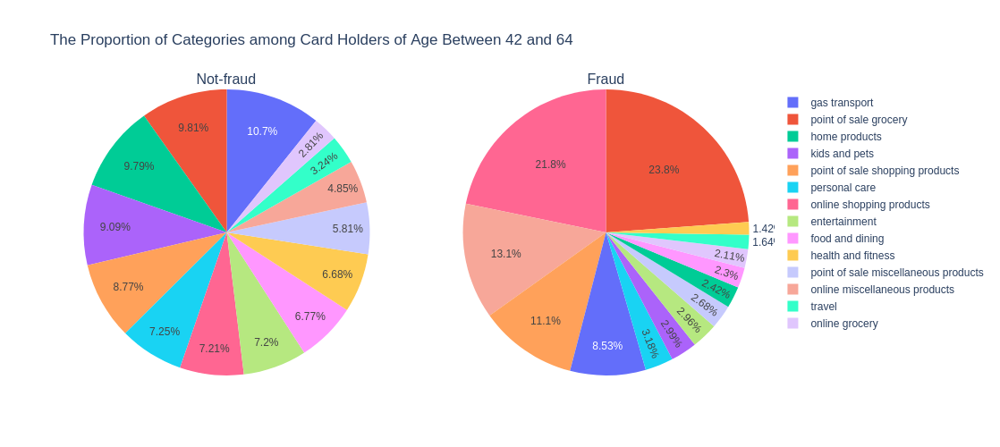

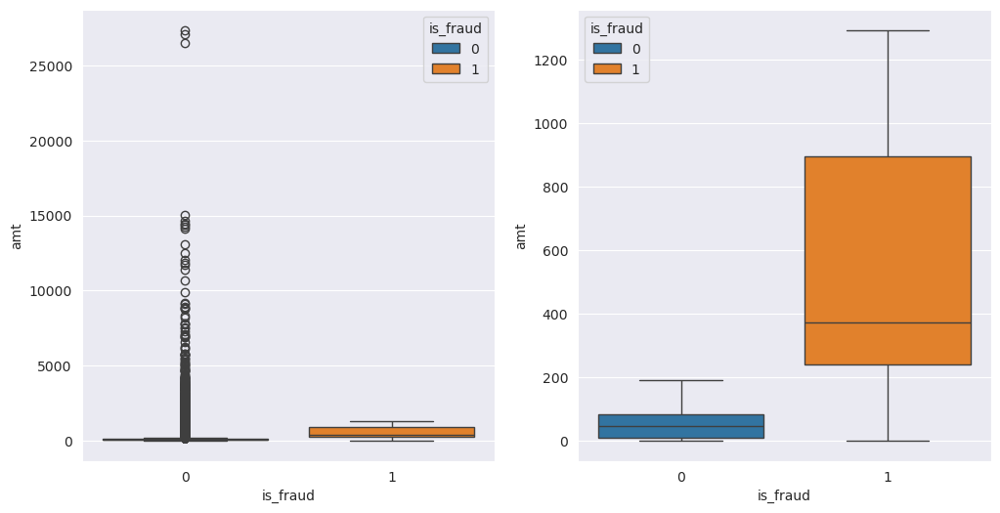

In [30]:
# age: 42-64
age_grp = [42, 64]

df = df_age.loc[(df_age['cardholder_age'] >= age_grp[0]) & (df_age['cardholder_age'] <= age_grp[1])]
df_age_nonFraud = df.loc[df['is_fraud']==0]
df_age_Fraud = df.loc[df['is_fraud']==1]

nonFraud_values = df_age_nonFraud['category'].value_counts().values
nonFraud_label = list(df_age_nonFraud['category'].value_counts().index)
Fraud_values = df_age_Fraud['category'].value_counts().values
Fraud_label = list(df_age_Fraud['category'].value_counts().index)

fig = make_subplots(1, 2, specs=[[{'type': 'domain'}, {'type': 'domain'}]],
                    subplot_titles=['Not-fraud', 'Fraud'])

fig.add_trace(go.Pie(labels=nonFraud_label, values=nonFraud_values,
                     name=f"Age of Card Holder Between {age_grp[0]} and {age_grp[1]}, Not-fraud",
                     # marker=dict(colors=['#c7c03a', '#a407a4'])), 
                    ),
              1, 1)
fig.add_trace(go.Pie(labels=Fraud_label, values=Fraud_values,
                     name=f"Age of Card Holder Between {age_grp[0]} and {age_grp[1]}, Fraud",
                     # marker=dict(colors=['#c7c03a', '#a407a4'])), 
                    ),
              1, 2)

fig.update_layout(
    title_text=f"The Proportion of Categories among Card Holders of Age Between {age_grp[0]} and {age_grp[1]}",
    showlegend=True,  # Hide the legend if not needed
    uniformtext_minsize=12,  # Make sure text is visible
    uniformtext_mode='hide',  # Prevent overlapping text
    height=500,  # Set height to control overall plot size
    width=1000,   # Set width to ensure equal pie size
)

fig.show()

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(12,6))
s = sns.boxplot(ax=ax[0], x="is_fraud", y="amt", hue="is_fraud", data=df, showfliers=True)  # with outlier
s = sns.boxplot(ax=ax[1], x="is_fraud", y="amt", hue="is_fraud", data=df, showfliers=False) # without outlier
plt.show();

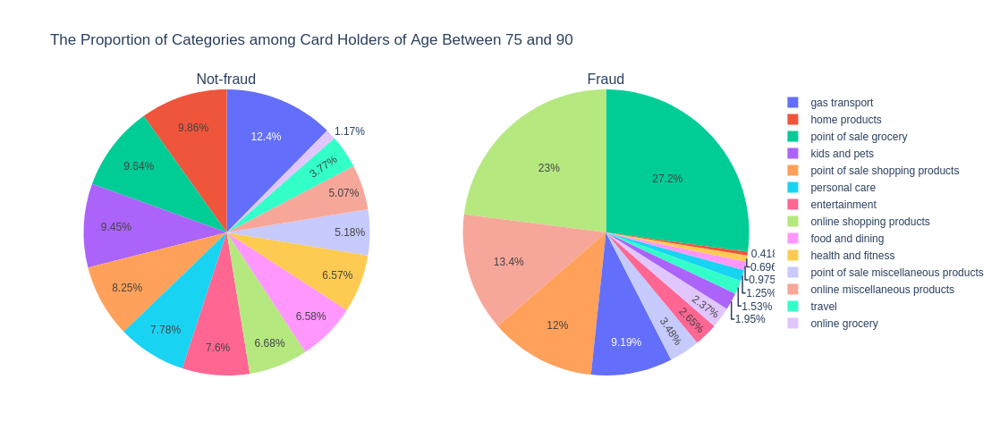

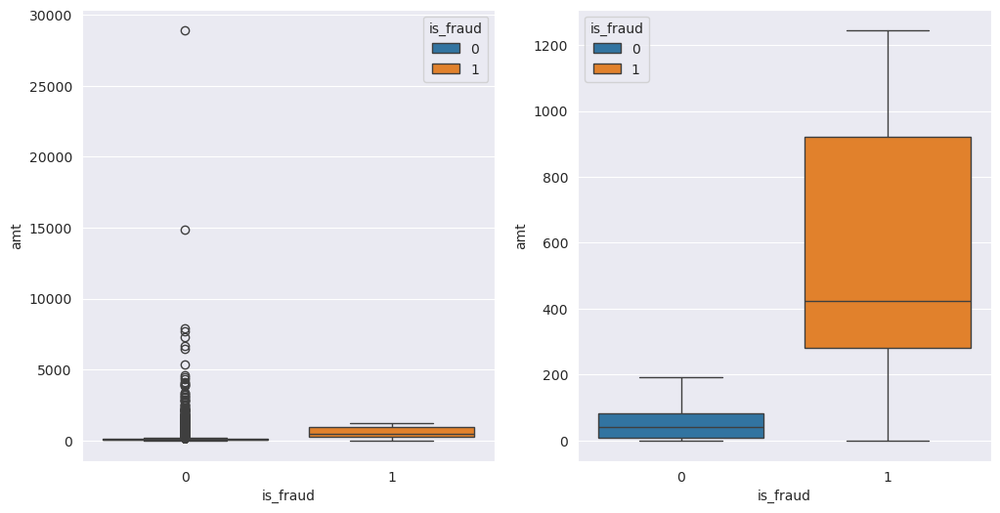

In [31]:
# age: 75-90
age_grp = [75, 90]

df = df_age.loc[(df_age['cardholder_age'] >= age_grp[0]) & (df_age['cardholder_age'] <= age_grp[1])]
df_age_nonFraud = df.loc[df['is_fraud']==0]
df_age_Fraud = df.loc[df['is_fraud']==1]

nonFraud_values = df_age_nonFraud['category'].value_counts().values
nonFraud_label = list(df_age_nonFraud['category'].value_counts().index)
Fraud_values = df_age_Fraud['category'].value_counts().values
Fraud_label = list(df_age_Fraud['category'].value_counts().index)

fig = make_subplots(1, 2, specs=[[{'type': 'domain'}, {'type': 'domain'}]],
                    subplot_titles=['Not-fraud', 'Fraud'])

fig.add_trace(go.Pie(labels=nonFraud_label, values=nonFraud_values,
                     name=f"Age of Card Holder Between {age_grp[0]} and {age_grp[1]}, Not-fraud",
                     # marker=dict(colors=['#c7c03a', '#a407a4'])), 
                    ),
              1, 1)
fig.add_trace(go.Pie(labels=Fraud_label, values=Fraud_values,
                     name=f"Age of Card Holder Between {age_grp[0]} and {age_grp[1]}, Fraud",
                     # marker=dict(colors=['#c7c03a', '#a407a4'])), 
                    ),
              1, 2)

fig.update_layout(
    title_text=f"The Proportion of Categories among Card Holders of Age Between {age_grp[0]} and {age_grp[1]}",
    showlegend=True,  # Hide the legend if not needed
    uniformtext_minsize=12,  # Make sure text is visible
    uniformtext_mode='hide',  # Prevent overlapping text
    height=500,  # Set height to control overall plot size
    width=1000,   # Set width to ensure equal pie size
)

fig.show()

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(12,6))
s = sns.boxplot(ax=ax[0], x="is_fraud", y="amt", hue="is_fraud", data=df, showfliers=True)  # with outlier
s = sns.boxplot(ax=ax[1], x="is_fraud", y="amt", hue="is_fraud", data=df, showfliers=False) # without outlier
plt.show();

##### time (bed, office, evening)

In [32]:
# classify transaction time into time groups (bed time, office hour, evening)
df_time_grp = data_df.copy()

df_time_grp['trans_date_trans_time'] = pd.to_datetime(df_time_grp['trans_date_trans_time']) # Convert 'trans_date_trans_time' to datetime format


df_time_grp['hour'] = df_time_grp['trans_date_trans_time'].dt.hour # Extract the hour from 'trans_date_trans_time'

def classify_time(hour):
    if 0 <= hour < 8:
        return "bed time"
    elif 8 <= hour < 16:
        return "office hour"
    else:
        return "evening"

df_time_grp['trans_time_grp'] = df_time_grp['hour'].apply(classify_time)

df_time_grp = df_time_grp.drop(columns=['hour'])

# df_time_grp.iloc[605:620, :]
# df_time_grp.iloc[1440:1450, :]
# df_time_grp

In [33]:
# classify card holder age into different age group
date_se = pd.to_datetime(data_df['trans_date_trans_time'])
dob_se = pd.to_datetime(data_df['dob'])

day_diff = (date_se - dob_se)

time_diff = day_diff.astype('int64')

age_arr = (time_diff/((10**6) * 60 * 60 * 24 * 365.25 *1000)).astype('int64') # convert microsecond to year, times 1000 at last to remove 000

df_time_grp['dob'] = age_arr
df_time_grp.rename(columns = {'dob':'cardholder_age'}, inplace = True)

df_time_grp['trans_year_month'] = df_time_grp['trans_date_trans_time'].dt.to_period('M')

def classify_age(age):
    if age < 19:
        return "13-19"
    elif 20 <= age <= 29:
        return "20-29"
    elif 30 <= age <= 39:
        return "30-39"
    elif 40 <= age <= 49:
        return "40-49"
    elif 50 <= age <= 59:
        return "50-59"
    elif 60 <= age <= 69:
        return "60-69"
    elif 70 <= age <= 79:
        return "70-79"
    elif 80 <= age <= 89:
        return "80-89"
    else: # 90-95
        return "90-95"
      
df_time_grp['age_grp'] = df_time_grp['cardholder_age'].apply(classify_age)

df_bed = df_time_grp.loc[df_time_grp["trans_time_grp"]=="bed time"]
df_office = df_time_grp.loc[df_time_grp["trans_time_grp"]=="office hour"]
df_evening = df_time_grp.loc[df_time_grp["trans_time_grp"]=="evening"]

trans_year_month,total_counts,fraud_counts,non_fraud_counts,fraud_perc
2019-01\n(day 0 to 30),52525,506,52019,0.963351
2019-02\n(day 31 to 58),49866,517,49349,1.036779
2019-03\n(day 59 to 89),70939,494,70445,0.696373
2019-04\n(day 90 to 119),68078,376,67702,0.552308
2019-05\n(day 120 to 150),72532,408,72124,0.562510
2019-06\n(day 151 to 180),86064,354,85710,0.411322
2019-07\n(day 181 to 211),86596,331,86265,0.382235
2019-08\n(day 212 to 242),87359,382,86977,0.437276
2019-09\n(day 243 to 272),70652,418,70234,0.591632
2019-10\n(day 273 to 303),68758,454,68304,0.660287


/tmp/ipykernel_3058192/648630632.py:51: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




0.6096141491582763


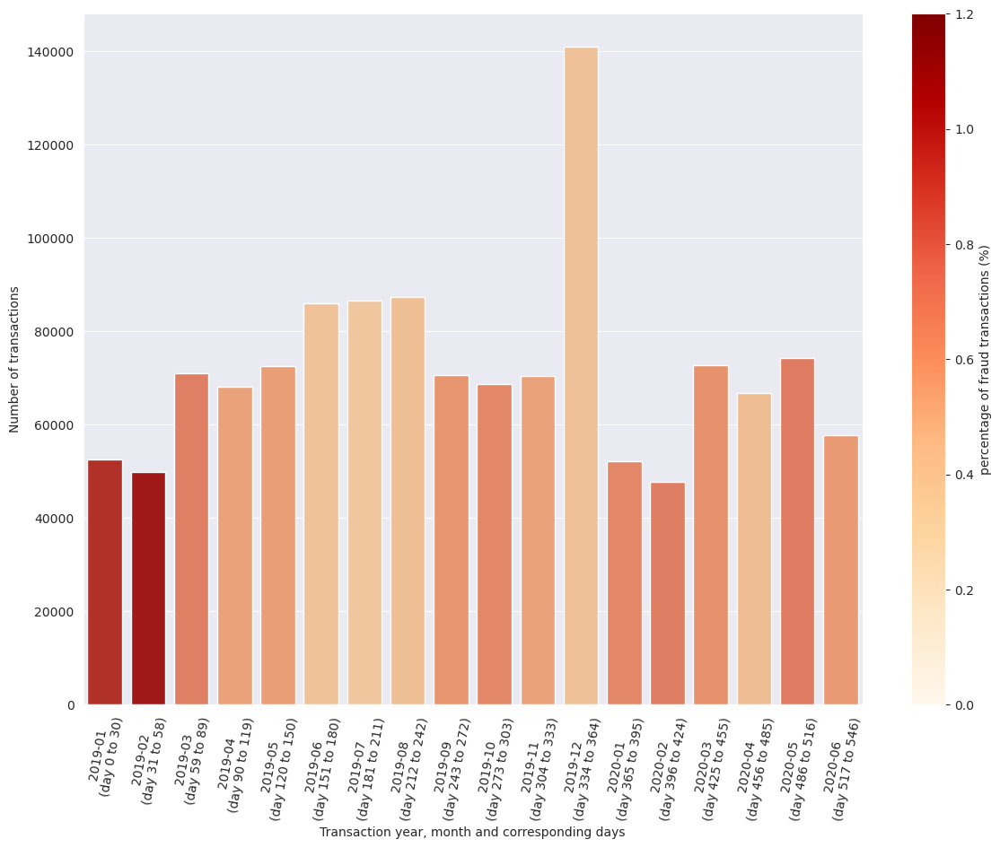

In [34]:
# time_month
df_year_fraud_perc = pd.DataFrame({'total_counts' : df_time_grp.groupby(['trans_year_month']).size()}).reset_index()

year_fraud_dict = {}
for year_month in df_year_fraud_perc['trans_year_month']:
    df = df_time_grp.loc[df_time_grp['trans_year_month']==year_month]
    year_nonFraud, year_Fraud = df['is_fraud'].value_counts().values
    year_fraud_dict[year_month] = year_Fraud

df_year_fraud_perc['fraud_counts'] = year_fraud_dict.values()
df_year_fraud_perc['non_fraud_counts'] = df_year_fraud_perc['total_counts'] - df_year_fraud_perc['fraud_counts']

df_year_fraud_perc['fraud_perc'] = (np.array(list(year_fraud_dict.values()))/df_year_fraud_perc['total_counts'])*100
df_year_fraud_perc['fraud_perc'] = df_year_fraud_perc['fraud_perc'].astype('float')

days_list = ['\n(day 0 to 30)',
 '\n(day 31 to 58)',
 '\n(day 59 to 89)',
 '\n(day 90 to 119)',
 '\n(day 120 to 150)',
 '\n(day 151 to 180)',
 '\n(day 181 to 211)',
 '\n(day 212 to 242)',
 '\n(day 243 to 272)',
 '\n(day 273 to 303)',
 '\n(day 304 to 333)',
 '\n(day 334 to 364)',
 '\n(day 365 to 395)',
 '\n(day 396 to 424)',
 '\n(day 425 to 455)',
 '\n(day 456 to 485)',
 '\n(day 486 to 516)',
 '\n(day 517 to 546)']

yr_mnth_day_list = []
for i in range(0, len(days_list)):
    # print(df_year_fraud_perc['trans_year_month'][i], days_list[i])
    yr_mnth_day = str(df_year_fraud_perc['trans_year_month'][i]) + str(days_list[i])
    yr_mnth_day_list.append(yr_mnth_day)
df_year_fraud_perc['trans_year_month'] = yr_mnth_day_list

display(HTML(df_year_fraud_perc.to_html(index=False)))


norm = plt.Normalize(0, 1.2)
sm = plt.cm.ScalarMappable(cmap="OrRd", norm=norm)

plt.figure(figsize=(14, 10))
colors = list(plt.cm.OrRd(norm(df_year_fraud_perc['fraud_perc'])))

bar = sns.barplot(x='trans_year_month', y='total_counts', data=df_year_fraud_perc, palette=colors)

cbar = plt.colorbar(sm, ax=bar)
cbar.set_label('percentage of fraud transactions (%)')

bar.tick_params(axis='x', labelrotation=80)
bar.set_ylabel('Number of transactions')
bar.set_xlabel('Transaction year, month and corresponding days')

# i = 0
# for p in bar.patches: # add annotation of percentage
#     height = p.get_height()
#     fraud_percentage = df_year_fraud_perc['fraud_perc'].iloc[i]
#     bar.annotate(f'{fraud_percentage:.2f}%', 
#                  (p.get_x() + p.get_width() / 2., height / 2), 
#                  ha='center', va='center', 
#                  fontsize=10, 
#                  color='black', 
#                  xytext=(0, 5),
#                  textcoords='offset points')
#     i = i+1

print(df_year_fraud_perc['fraud_perc'].mean())

plt.show()

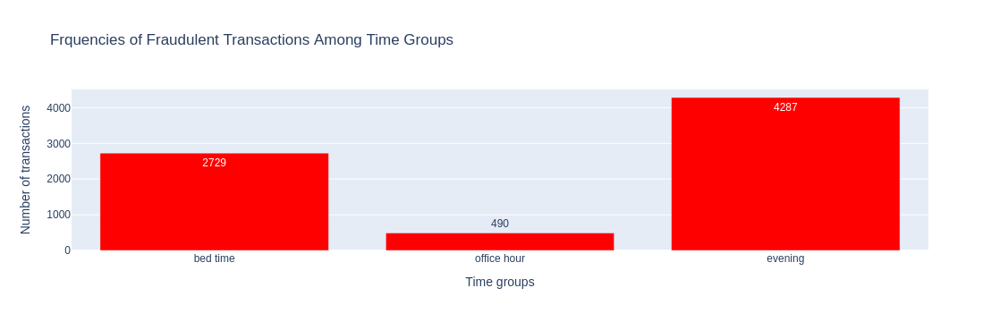

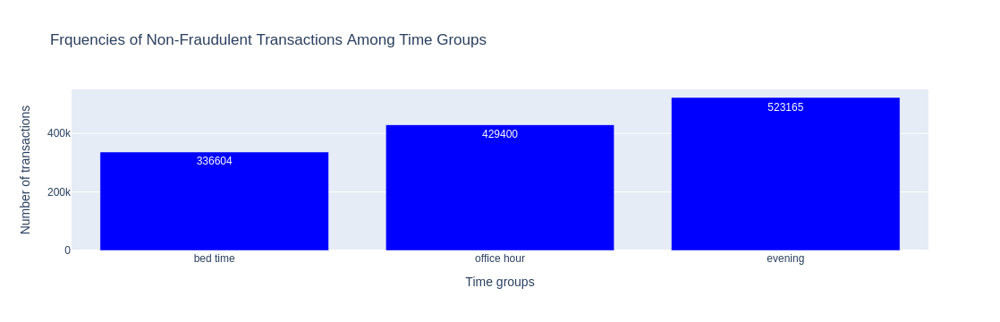

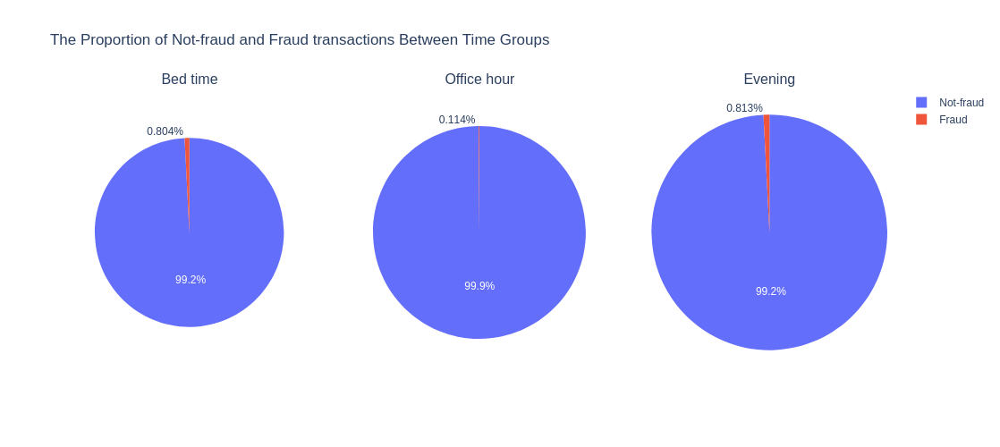

In [35]:
# plot bar chart
fraud_bed = df_bed['is_fraud'].value_counts().values[1]
fraud_office = df_office['is_fraud'].value_counts().values[1]
fraud_evening = df_evening['is_fraud'].value_counts().values[1]

labels = ['bed time', 'office hour', 'evening']
values = [fraud_bed, fraud_office, fraud_evening]

trace = go.Bar(
    x=labels, y=values,
    name="Frquencies of Fraud Transactions Among Time Groups",
    marker=dict(color="Red"),
    text=values
)

data = [trace]
layout = dict(title = 'Frquencies of Fraudulent Transactions Among Time Groups',
          xaxis = dict(title = 'Time groups', showticklabels=True),
          yaxis = dict(title = 'Number of transactions'),
          hovermode = 'closest',width=700
         )
fig = dict(data=data, layout=layout)
iplot(fig, filename='class') # use plotly


fraud_bed = df_bed['is_fraud'].value_counts().values[0]
fraud_office = df_office['is_fraud'].value_counts().values[0]
fraud_evening = df_evening['is_fraud'].value_counts().values[0]

labels = ['bed time', 'office hour', 'evening']
values = [fraud_bed, fraud_office, fraud_evening]

trace = go.Bar(
    x=labels, y=values,
    name="Frquencies of Fraud Transactions Among Time Groups",
    marker=dict(color="Blue"),
    text=values
)

data = [trace]
layout = dict(title = 'Frquencies of Non-Fraudulent Transactions Among Time Groups',
          xaxis = dict(title = 'Time groups', showticklabels=True),
          yaxis = dict(title = 'Number of transactions'),
          hovermode = 'closest', width=700
         )
fig = dict(data=data, layout=layout)
iplot(fig, filename='class') # use plotly

# time_grp vs fraud
bed_values = df_bed['is_fraud'].value_counts().values
office_values = df_office['is_fraud'].value_counts().values
evening_values = df_evening['is_fraud'].value_counts().values

labels = ["Not-fraud", "Fraud"]


fig = make_subplots(1, 3, specs=[[{'type': 'domain'}, {'type': 'domain'}, {'type': 'domain'}]],
                    subplot_titles=['Bed time', 'Office hour', 'Evening'])

fig.add_trace(go.Pie(labels=labels, values=bed_values,
                     name="Bed Time Distribution", scalegroup='one'
                    ),
                     # marker=dict(colors=['#c7c03a', '#a407a4'])),
              1, 1)
fig.add_trace(go.Pie(labels=labels, values=office_values,
                     name="Office Hour Distribution", scalegroup='one'
                     ),
                     # marker=dict(colors=['#c7c03a', '#a407a4'])),
              1, 2)
fig.add_trace(go.Pie(labels=labels, values=evening_values,
                     name="Evening Distribution", scalegroup='one'
                     ),
                     # marker=dict(colors=['#c7c03a', '#a407a4'])),
              1, 3)

fig.update_layout(
    title_text=f"The Proportion of Not-fraud and Fraud transactions Between Time Groups",
    showlegend=True,  # Hide the legend if not needed
    uniformtext_minsize=12,  # Make sure text is visible
    uniformtext_mode='hide',  # Prevent overlapping text
    height=500,  # Set height to control overall plot size
    width=1000,   # Set width to ensure equal pie size
)

fig.show()

<Axes: xlabel='trans_time_grp', ylabel='amt'>

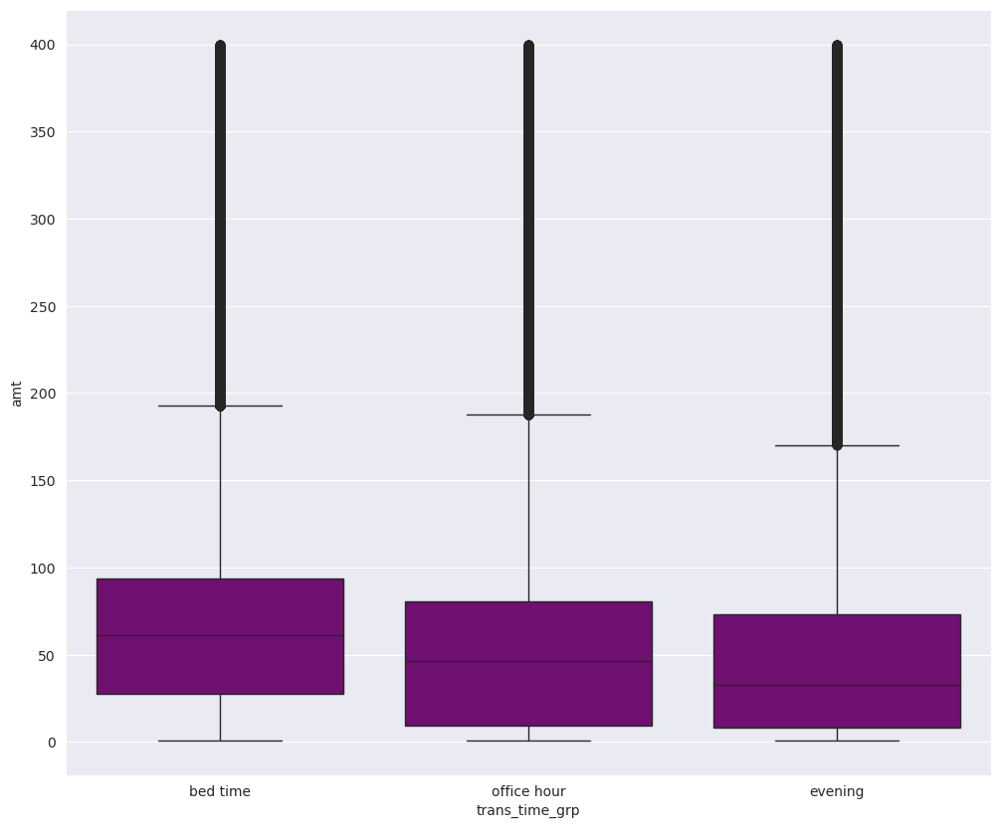

In [36]:
# time_grp
plt.figure(figsize=(12, 10))

# sns.displot(data=df_time_grp.loc[df_time_grp['amt']<400], x="amt", hue="trans_time_grp")

sns.boxplot(data=df_time_grp.loc[df_time_grp['amt']<400], x="trans_time_grp", y="amt", color="purple", showfliers=True)
# s = sns.boxplot(x="is_fraud", y="amt", hue="is_fraud", data=df, showfliers=True)  # with outlier

age_grp
40-49    67967
50-59    66224
30-39    63268
60-69    48467
20-29    39818
70-79    26025
80-89    15329
90-95     9350
13-19     2885
Name: count, dtype: int64
[67967 66224 63268 48467 39818 26025 15329  9350  2885]
['40-49', '50-59', '30-39', '60-69', '20-29', '70-79', '80-89', '90-95', '13-19']
age_grp
40-49    100577
30-39     97067
20-29     69106
50-59     61266
60-69     45235
70-79     24296
80-89     14057
90-95     11286
13-19      7000
Name: count, dtype: int64
[100577  97067  69106  61266  45235  24296  14057  11286   7000]
['40-49', '30-39', '20-29', '50-59', '60-69', '70-79', '80-89', '90-95', '13-19']
age_grp
40-49    135792
30-39    130967
20-29    100303
50-59     57457
60-69     42794
70-79     22561
90-95     13391
80-89     12923
13-19     11264
Name: count, dtype: int64
[135792 130967 100303  57457  42794  22561  13391  12923  11264]
['40-49', '30-39', '20-29', '50-59', '60-69', '70-79', '90-95', '80-89', '13-19']


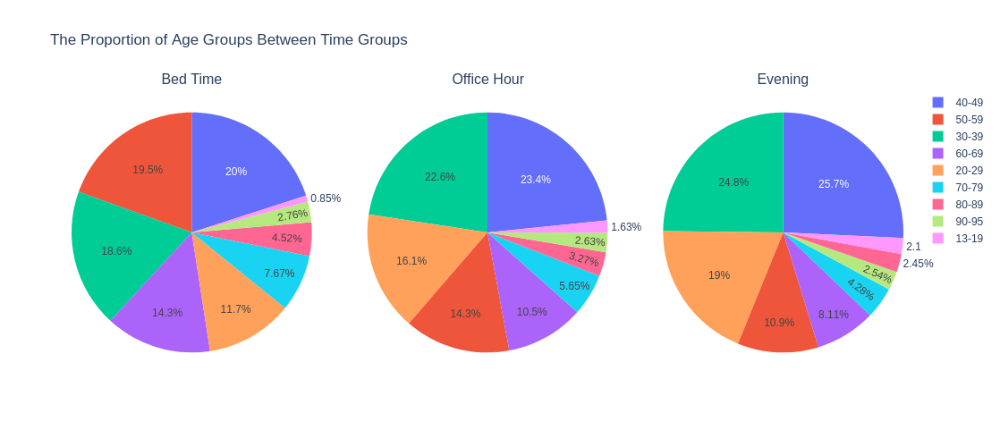

In [37]:
# time_grp vs age_grp
bed_values = df_bed['age_grp'].value_counts().values
bed_labels = list(df_bed['age_grp'].value_counts().index)
office_values = df_office['age_grp'].value_counts().values
office_labels = list(df_office['age_grp'].value_counts().index)
evening_values = df_evening['age_grp'].value_counts().values
evening_labels = list(df_evening['age_grp'].value_counts().index)

print(df_bed['age_grp'].value_counts())
print(bed_values)
print(bed_labels)
print(df_office['age_grp'].value_counts())
print(office_values)
print(office_labels)
print(df_evening['age_grp'].value_counts())
print(evening_values)
print(evening_labels)

fig = make_subplots(1, 3, specs=[[{'type': 'domain'}, {'type': 'domain'}, {'type': 'domain'}]],
                    subplot_titles=['Bed Time', 'Office Hour', 'Evening'])

fig.add_trace(go.Pie(labels=bed_labels, values=bed_values,
                     name=f"Bed Time Distribution"
                    ),
                     # marker=dict(colors=['#c7c03a', '#a407a4'])),
              1, 1)
fig.add_trace(go.Pie(labels=office_labels, values=office_values,
                     name=f"Office Hour Distribution"
                     ),
                     # marker=dict(colors=['#c7c03a', '#a407a4'])),
              1, 2)
fig.add_trace(go.Pie(labels=evening_labels, values=evening_values,
                     name=f"Evening Distribution"
                     ),
                     # marker=dict(colors=['#c7c03a', '#a407a4'])),
              1, 3)

fig.update_layout(
    title_text=f"The Proportion of Age Groups Between Time Groups",
    showlegend=True,  # Hide the legend if not needed
    uniformtext_minsize=12,  # Make sure text is visible
    uniformtext_mode='hide',  # Prevent overlapping text
    height=500,  # Set height to control overall plot size
    width=1000,   # Set width to ensure equal pie size
)

fig.show()

##### age grp, amount of money, time group and category

Text(0, 0.5, 'Amount spent (USD)')

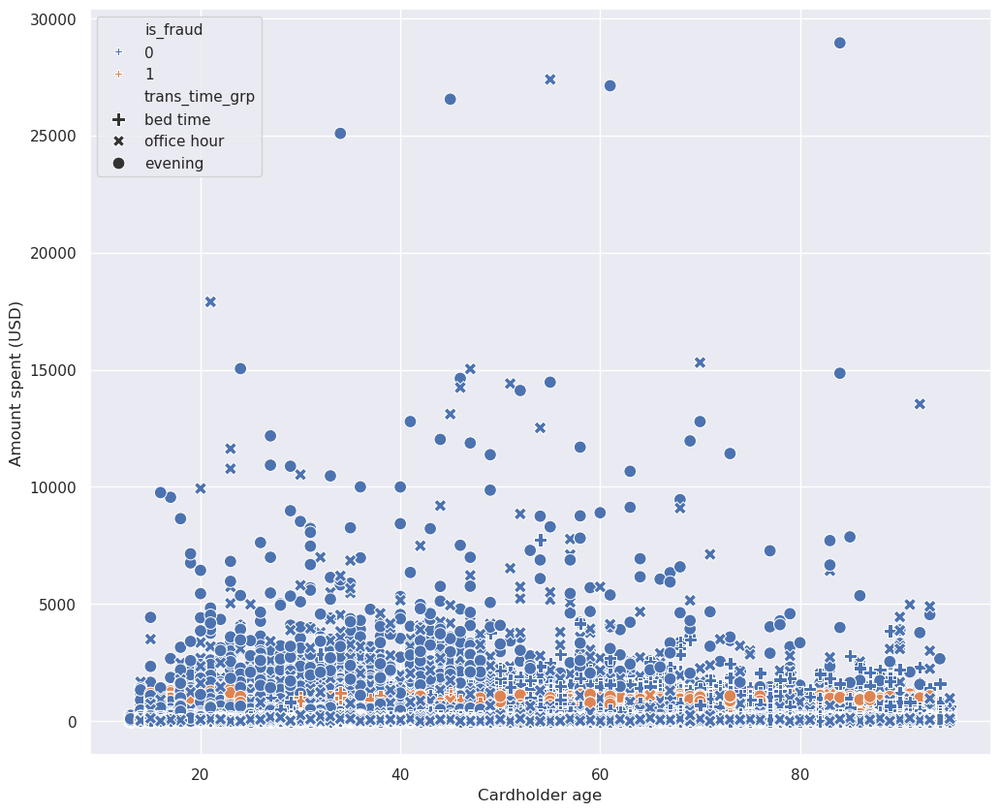

In [38]:
# time_grp vs amt vs age, with outlier
df = df_time_grp.copy() # full data, show outlier

sns.set_theme(rc={'figure.figsize':(12, 10)})

markers = {"evening": "o", "office hour": "X", "bed time": "P"}
sns.scatterplot(data=df, x="cardholder_age", y="amt",
                hue="is_fraud", legend="full",
                # style="trans_time_grp", size="trans_time_grp", sizes=(30,40))
                style="trans_time_grp", markers=markers, size="trans_time_grp", sizes=(85,90))

plt.xlabel('Cardholder age')
plt.ylabel('Amount spent (USD)')

In [39]:
(1575/(data_df.shape[0]))*100

0.12146451500954364

For Outliers:
category
point of sale shopping products         609
online shopping products                436
travel                                  386
point of sale miscellaneous products     87
online miscellaneous products            57
Name: count, dtype: int64


count    1575.000000
mean       43.799365
std        17.103033
min        14.000000
25%        31.000000
50%        42.000000
75%        53.000000
max        94.000000
Name: cardholder_age, dtype: float64




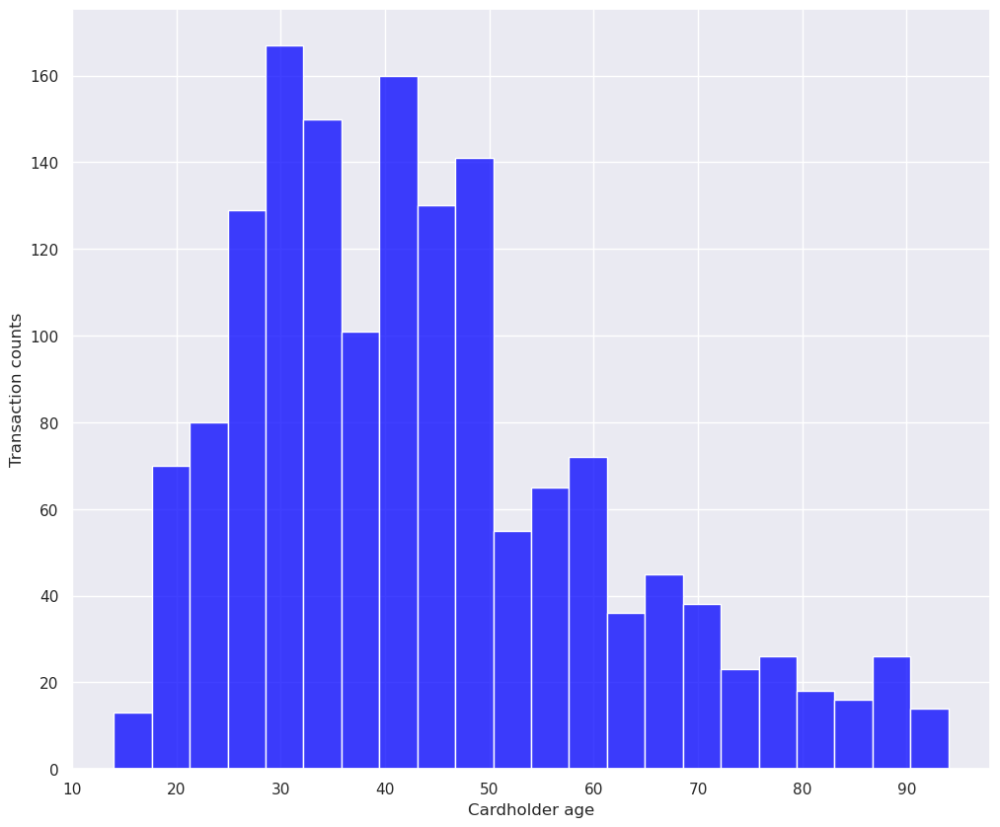

trans_time_grp
evening        883
office hour    499
bed time       193
Name: count, dtype: int64


In [40]:
df = df_time_grp.loc[data_df['amt']>1376.04]

sns.set_theme(rc={'figure.figsize':(12, 10)})

print("For Outliers:")
print(df['category'].value_counts())
print("\n")

print(df['cardholder_age'].describe())
print("\n")
fig1 = sns.histplot(data=df, x="cardholder_age", color="blue")
fig1.set(xlabel="Cardholder age", ylabel="Transaction counts")
plt.show()

print(df['trans_time_grp'].value_counts())

We removed 731 no. of records, which is 0.05637495902982628% of data, so we remain 99.94362504097018% of data


Text(0, 0.5, 'Amount spent (USD)')

~/anaconda3/envs/myenv1/lib/python3.11/site-packages/IPython/core/events.py:82: UserWarning:

Creating legend with loc="best" can be slow with large amounts of data.

~/anaconda3/envs/myenv1/lib/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWarning:

Creating legend with loc="best" can be slow with large amounts of data.



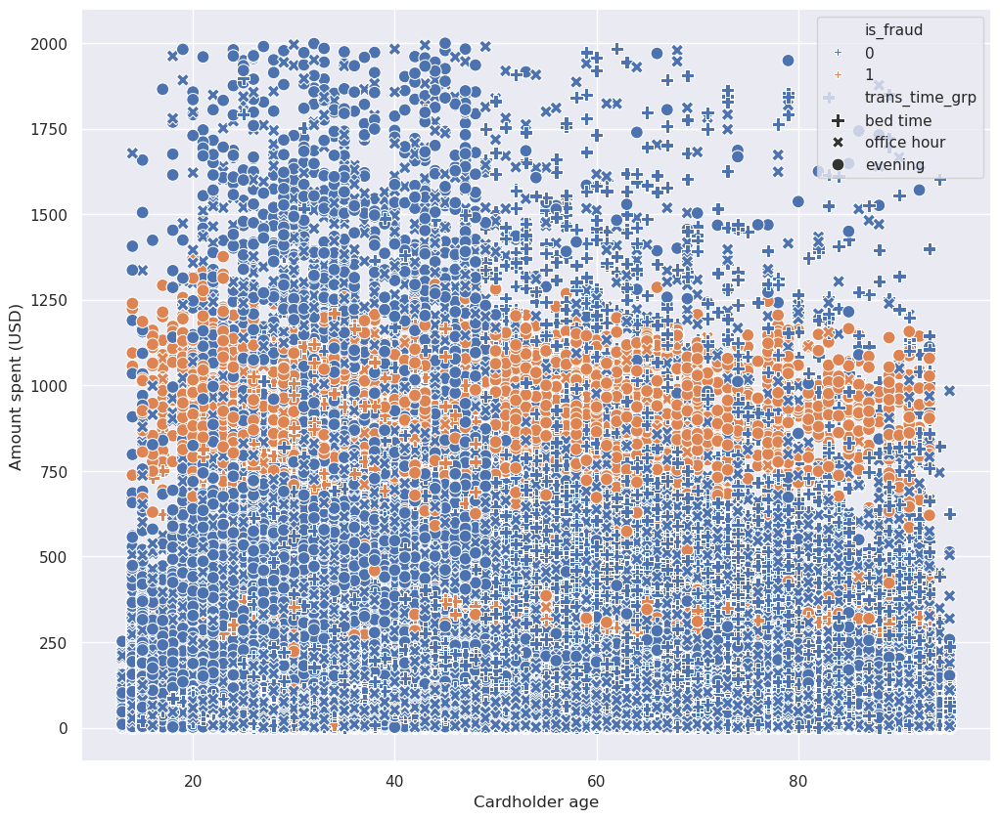

In [41]:
# time_grp vs amt vs age, without outlier
df = df_time_grp.loc[df_time_grp['amt'] < 2000] # remove 'amt' outlier (max of fraud is $1376.04 )
# df_1, df_2 = train_test_split(df, test_size=0.5,random_state=RANDOM_STATE, shuffle=True)

entries_removed = df_time_grp.shape[0] - df.shape[0]
remove_perc = ((entries_removed / df_time_grp.shape[0])*100)
print(f"We removed {entries_removed} no. of records, which is {remove_perc}% of data, so we remain {100-remove_perc}% of data")

sns.set_theme(rc={'figure.figsize':(12, 10)})

markers = {"evening": "o", "office hour": "X", "bed time": "P"}
sns.scatterplot(data=df, x="cardholder_age", y="amt",
                hue="is_fraud", legend="full",
                # style="trans_time_grp", size="trans_time_grp", sizes=(30,40))
                style="trans_time_grp", markers=markers, size="trans_time_grp", sizes=(85,90))

plt.xlabel('Cardholder age')
plt.ylabel('Amount spent (USD)')

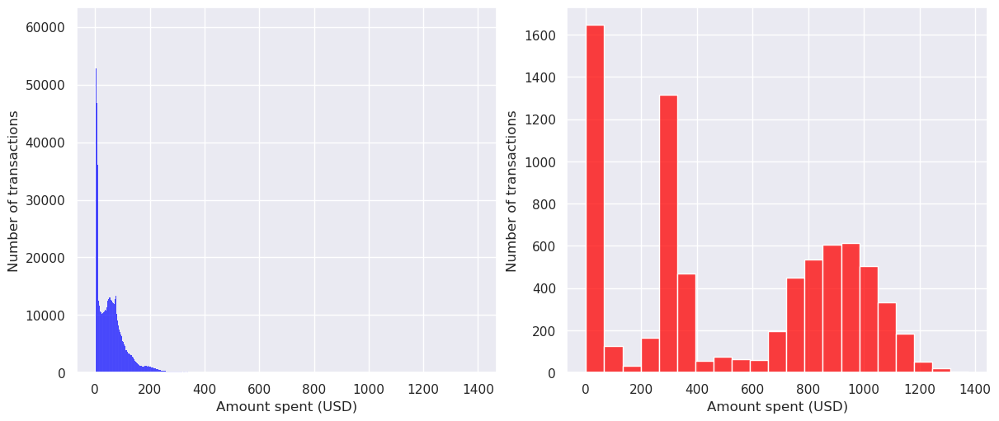

In [42]:
# def classify_amt(amt):
#     if amt <= 250:
#         return '0-250'
#     elif 251 <= amt <= 500:
#     	return '251-500'
#     elif 501 <= amt <= 750:
#     	return '501-750'
#     elif 751 <= amt <= 1000:
#     	return '751-1000'
#     elif 1001 <= amt <= 1250:
#     	return '1001-1250'
#     elif 1251 <= amt <= 1500:
#     	return '1251-1500'
#     else:
#         return '>1500'

# df_time_grp['amt_grp'] = df_time_grp['amt'].apply(classify_amt)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)

# dist1 = sns.displot(data=df_time_grp.loc[df_time_grp['is_fraud'] == 0].loc[df_time_grp['amt']<1400], x="amt", color="blue") # limiting to below $1400
# dist1.set(xlabel="Amount spent (USD)", ylabel="number of transactions")
# dist2 = sns.displot(data=df_time_grp.loc[df_time_grp['is_fraud'] == 1], x="amt", color="red")
# dist2.set(xlabel="Amount spent (USD)", ylabel="number of transactions")

dist1 = sns.histplot(data=df_time_grp.loc[df_time_grp['is_fraud'] == 0].loc[df_time_grp['amt']<1400], ax=axes[0], 
                    x="amt", color="blue") # limiting to below $1400
dist1.set(xlabel="Amount spent (USD)", ylabel="Number of transactions")
dist2 = sns.histplot(data=df_time_grp.loc[df_time_grp['is_fraud'] == 1], ax=axes[1],
                    x="amt", color="red")
dist2.set(xlabel="Amount spent (USD)", ylabel="Number of transactions")

plt.show()

Text(0, 0.5, 'Number of transactions')

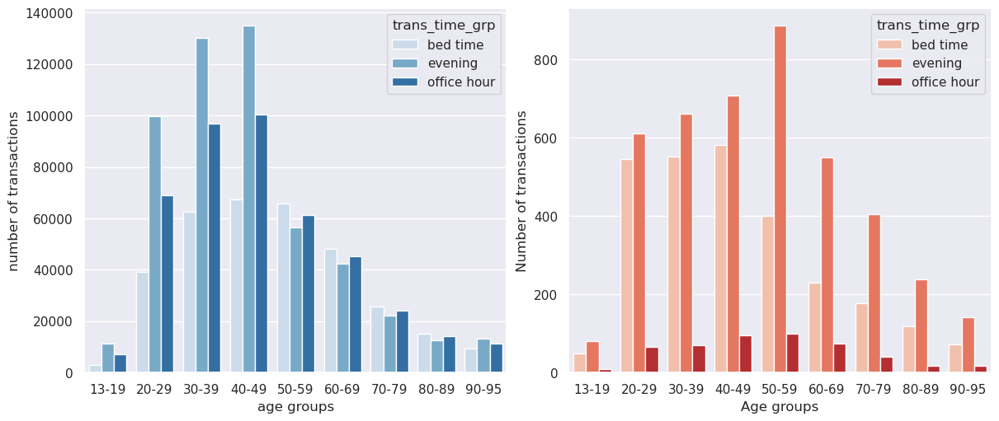

In [43]:
df_NonFraud = df_time_grp.loc[df_time_grp['is_fraud']==0]
df_NonFraud.groupby(['age_grp','trans_time_grp']).size()

df = pd.DataFrame({'count' : df_NonFraud.groupby(['age_grp','trans_time_grp']).size()}).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)

graph1 = sns.barplot(data=df, x="age_grp", y="count", ax=axes[0],
            hue="trans_time_grp", palette="Blues")
graph1.set_xlabel("age groups")
graph1.set_ylabel("number of transactions")

df_Fraud = df_time_grp.loc[df_time_grp['is_fraud']==1]
df_Fraud.groupby(['age_grp','trans_time_grp']).size()

df = pd.DataFrame({'count' : df_Fraud.groupby(['age_grp','trans_time_grp']).size()}).reset_index()

graph2 = sns.barplot(data=df, x="age_grp", y="count", ax=axes[1],
            hue="trans_time_grp", palette="Reds")
graph2.set_xlabel("Age groups")
graph2.set_ylabel("Number of transactions")

We removed 731 no. of records, which is 0.05637495902982628% of data, so we remain 99.94362504097018% of data


Text(6659.173527990361, 0.5, 'Amount spent (USD)')

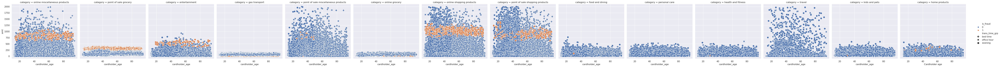

In [44]:
# time_grp vs amt vs age, without outlier, category relplot

df = df_time_grp.loc[df_time_grp['amt'] < 2000] # remove 'amt' outlier (max of fraud is $1376.04 )
# df_1, df_2 = train_test_split(df, test_size=0.1,random_state=RANDOM_STATE, shuffle=True)

entries_removed = df_time_grp.shape[0] - df.shape[0]
remove_perc = ((entries_removed / df_time_grp.shape[0])*100)
print(f"We removed {entries_removed} no. of records, which is {remove_perc}% of data, so we remain {100-remove_perc}% of data")

sns.set_theme(rc={'figure.figsize':(12, 40)})

markers = {"evening": "o", "office hour": "X", "bed time": "P"}
sns.relplot(data=df, x="cardholder_age", y="amt",
                col="category",
                hue="is_fraud", legend="full", style="trans_time_grp",
                markers=markers, size="trans_time_grp", sizes=(85,90))

plt.xlabel('Cardholder age')
plt.ylabel('Amount spent (USD)')

In [50]:
df['category'].unique()

array(['online miscellaneous products', 'point of sale grocery',
       'entertainment', 'gas transport',
       'point of sale miscellaneous products', 'online grocery',
       'online shopping products', 'point of sale shopping products',
       'food and dining', 'personal care', 'health and fitness', 'travel',
       'kids and pets', 'home products'], dtype=object)

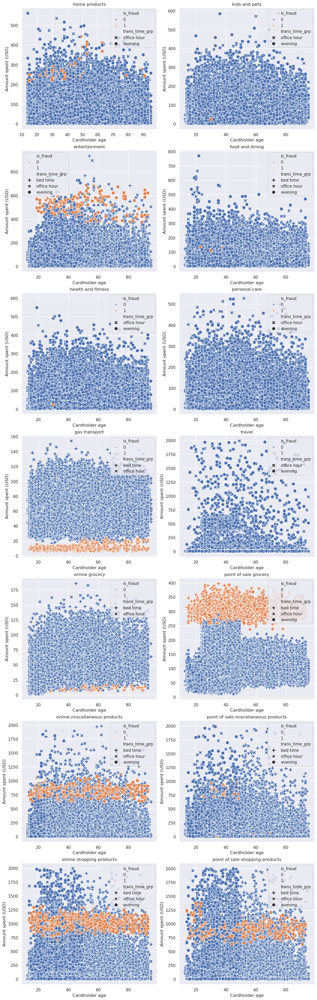

In [54]:
# time_grp vs amt vs age, without outlier
df = df_time_grp.loc[df_time_grp['amt'] < 2000] # remove 'amt' outlier (max of fraud is $1376.04 )
# df_1, df_2 = train_test_split(df, test_size=0.1, random_state=RANDOM_STATE, shuffle=True)

# entries_removed = df_time_grp.shape[0] - df.shape[0]
# remove_perc = ((entries_removed / df_time_grp.shape[0])*100)
# print(f"We removed {entries_removed} no. of records, which is {remove_perc}% of data, so we remain {100-remove_perc}% of data")

# sns.set_theme(rc={'figure.figsize':(20, 20)})
fig, axes = plt.subplots(7, 2, figsize=(12, 38), constrained_layout=True)
# fig.tight_layout()

category_list = ["home products", "kids and pets", "entertainment", "food and dining", "health and fitness", "personal care", "gas transport", "travel", 
                 "online grocery", "point of sale grocery", "online miscellaneous products", "point of sale miscellaneous products", "online shopping products", "point of sale shopping products"] # order following the encoding order

markers = {"evening": "o", "office hour": "X", "bed time": "P"}

c = 0

for i in range(0, 7):
    for j in range(0, 2):
        my_cat = category_list[c]
        sns.scatterplot(data=df.loc[df['category']==my_cat], ax=axes[i,j],
                        x="cardholder_age", y="amt",
                        hue="is_fraud", legend="full", style="trans_time_grp",
                        markers=markers, size="trans_time_grp", sizes=(85,90))
        axes[i,j].set_title(my_cat)
        axes[i,j].set(xlabel='Cardholder age', ylabel='Amount spent (USD)')
        c = c+1

In [46]:
# Filtering
category_value = None
age_limit = None
time_group_value = None
fraud_status = 1
amt_limit = None

filtered_df = df_time_grp.copy()

if category_value != None:
    filtered_df = filtered_df[filtered_df['category'] == category_value]
if age_limit != None:
    filtered_df = filtered_df[(filtered_df['cardholder_age'] >= age_limit[0]) & (filtered_df['cardholder_age'] < age_limit[1])]
if time_group_value != None:
    filtered_df = filtered_df[filtered_df['trans_time_grp'] == time_group_value]
if fraud_status != None:
    filtered_df = filtered_df[filtered_df['is_fraud'] == fraud_status]
if amt_limit != None:
    filtered_df = filtered_df[(filtered_df['amt'] >= amt_limit[0]) & (filtered_df['amt'] < amt_limit[1])]

number_of_rows = filtered_df.shape[0]
print(number_of_rows)

print("Amt: min is", filtered_df['amt'].min(),"max is", filtered_df['amt'].max())

filtered_df

7506
Amt: min is 1.06 max is 1376.04


,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,city,state,zip,lat,long,city_pop,job,cardholder_age,trans_num,unix_time,merch_lat,merch_long,is_fraud,trans_time_grp,trans_year_month,age_grp
2449,2449,2019-01-02 01:06:37,4613314721966,fraud_Rutherford-Mertz,point of sale grocery,281.06,Jason,Murphy,M,542 Steve Curve Suite 011,Collettsville,NC,28611,35.9946,-81.7266,885,Soil scientist,30,e8a81877ae9a0a7f883e15cb39dc4022,1325466397,36.430124,-81.179483,1,bed time,2019-01,30-39
2472,2472,2019-01-02 01:47:29,340187018810220,"fraud_Jenkins, Hauck and Friesen",gas transport,11.52,Misty,Hart,F,27954 Hall Mill Suite 575,San Antonio,TX,78208,29.4400,-98.4590,1595797,Horticultural consultant,58,bc7d41c41103877b03232f03f1f8d3f5,1325468849,29.819364,-99.142791,1,bed time,2019-01,50-59
2523,2523,2019-01-02 03:05:23,340187018810220,fraud_Goodwin-Nitzsche,point of sale grocery,276.31,Misty,Hart,F,27954 Hall Mill Suite 575,San Antonio,TX,78208,29.4400,-98.4590,1595797,Horticultural consultant,58,b98f12f4168391b2203238813df5aa8c,1325473523,29.273085,-98.836360,1,bed time,2019-01,50-59
2546,2546,2019-01-02 03:38:03,4613314721966,fraud_Erdman-Kertzmann,gas transport,7.03,Jason,Murphy,M,542 Steve Curve Suite 011,Collettsville,NC,28611,35.9946,-81.7266,885,Soil scientist,30,397894a5c4c02e3c61c784001f0f14e4,1325475483,35.909292,-82.091010,1,bed time,2019-01,30-39
2553,2553,2019-01-02 03:55:47,340187018810220,fraud_Koepp-Parker,point of sale grocery,275.73,Misty,Hart,F,27954 Hall Mill Suite 575,San Antonio,TX,78208,29.4400,-98.4590,1595797,Horticultural consultant,58,7863235a750d73a244c07f1fb7f0185a,1325476547,29.786426,-98.683410,1,bed time,2019-01,50-59
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1295399,1295399,2020-06-21 01:00:08,3524574586339330,fraud_Kassulke PLC,online shopping products,977.01,Ashley,Cabrera,F,94225 Smith Springs Apt. 617,Vero Beach,FL,32960,27.6330,-80.4031,105638,"Librarian, public",34,a83b093f0c1d9068fa0089f7c722615f,1371776408,26.888686,-80.834389,1,bed time,2020-06,30-39
1295491,1295491,2020-06-21 01:53:35,3524574586339330,fraud_Schumm PLC,online shopping products,1210.91,Ashley,Cabrera,F,94225 Smith Springs Apt. 617,Vero Beach,FL,32960,27.6330,-80.4031,105638,"Librarian, public",34,f75b35bed13b9e692f170dba45a15b21,1371779615,28.216707,-79.855648,1,bed time,2020-06,30-39
1295532,1295532,2020-06-21 02:16:56,4005676619255478,"fraud_Tillman, Dickinson and Labadie",gas transport,10.24,William,Perry,M,458 Phillips Island Apt. 768,Denham Springs,LA,70726,30.4590,-90.9027,71335,Herbalist,26,a0ba2472cd3fc9731f2a18d3f308f5c3,1371781016,29.700456,-91.361632,1,bed time,2020-06,20-29
1295666,1295666,2020-06-21 03:26:20,3560725013359375,fraud_Corwin-Collins,gas transport,21.69,Brooke,Smith,F,63542 Luna Brook Apt. 012,Notrees,TX,79759,31.8599,-102.7413,23,Cytogeneticist,50,daa281350b1e16093c7b4bf97bf4d6ed,1371785180,32.675272,-103.484949,1,bed time,2020-06,50-59


In [47]:
filtered_df.groupby(['is_fraud', 'trans_time_grp']).size()

is_fraud  trans_time_grp
1         bed time          2729
          evening           4287
          office hour        490
dtype: int64

In [48]:
print("Home: Evening percentage is", (82346/123115 * 100))
print("Home: Fraud below 55 y.o. among all frauds is",(88922/123115 * 100))
print("Home: Amt fraud min is 177.41 max is 443.25")
print("")
print("Entertainment: Amt fraud min is 337.24 max is 695.53")
print("Entertainment: Amt fraud below 50 y.o. min is 385.22 max is 625.06")
print("Entertainment: Amt fraud above 50 y.o. min is 337.24 max is 695.53")
print("")
print("Gas_transport: No evening in general")
print("Gas_transport: Amt non-fraud min is 17.0 max is 154.03")
print("Gas_transport: Amt fraud min is 5.93 max is 24.84, fraud takes low amt")
print("Gas_transport: Percentage of bed time among non-fraud is", (87457/131041 * 100))
print("Gas_transport: Percentage of bed time among fraud is", (586/618 * 100))
print("")
print("Grocery_net: Amt fraud min is 5.97 max is 18.24")
print("Grocery_net: Percentage of non-fraud with amt above 18.24 is", (43776/45318 * 100))
print("Grocery_net: It is rare to have non-fraud falling below the fraud range")
print("")
print("Grocery_pos: Amt fraud min is 237.04 max is 397.97")
print("Grocery_pos: All transactions below 237.04 are non-fraud")
print("Grocery_pos: Percentage of fraud with amt above 270 is", (1674/1686 * 100))
print("Grocery_pos: For transactions amt between 200 and 270, percentage of non-fraud is", (9884/9953 * 100))
print("Grocery_pos: For transactions amt between 200 and 270, percentage of 25 to 50 y.o. is", (9821/9953 * 100))
print("")
print("Misc_net: Amt fraud min is 576.1 max is 1112.91")
print("Misc_net: Percentage of evening among non-fraud is", (7459/62372 * 100))
print("Misc_net: Percentage of evening among fraud is", (663/915 * 100))
print("Misc_net: Above 25 y.o., percentage of evening among non-fraud is", (2995/55179 * 100))
print("Misc_net: Above 25 y.o., percentage of evening among fraud is", (622/810 * 100))
print("")
print("Shopping_net: Amt fraud min is 711.2 max is 1312.98")
print("Shopping_net: Percentage of evening among fraud is", (1418/1713 * 100))
print("Shopping_net: Above 50 y.o., percentage of evening among non-fraud is", (0), ", none of them are in evening")
print("Shopping_net: Above 50 y.o., percentage of evening among fraud is", (738/800 * 100))
print("")
print("Shopping_pos: Amt fraud min is 598.9 max is 1376.04")
print("Shopping_pos: Percentage of evening among fraud is", (645/843 * 100))
print("Shopping_pos: Above 50 y.o., percentage of evening among non-fraud is", (0), ", none of them are in evening")
print("Shopping_pos: Above 50 y.o., percentage of evening among fraud is", (384/427 * 100))

Home: Evening percentage is 66.88543231937619
Home: Fraud below 55 y.o. among all frauds is 72.226779839987
Home: Amt fraud min is 177.41 max is 443.25

Entertainment: Amt fraud min is 337.24 max is 695.53
Entertainment: Amt fraud below 50 y.o. min is 385.22 max is 625.06
Entertainment: Amt fraud above 50 y.o. min is 337.24 max is 695.53

Gas_transport: No evening in general
Gas_transport: Amt non-fraud min is 17.0 max is 154.03
Gas_transport: Amt fraud min is 5.93 max is 24.84, fraud takes low amt
Gas_transport: Percentage of bed time among non-fraud is 66.7401805541777
Gas_transport: Percentage of bed time among fraud is 94.8220064724919

Grocery_net: Amt fraud min is 5.97 max is 18.24
Grocery_net: Percentage of non-fraud with amt above 18.24 is 96.59737852508937
Grocery_net: It is rare to have non-fraud falling below the fraud range

Grocery_pos: Amt fraud min is 237.04 max is 397.97
Grocery_pos: All transactions below 237.04 are non-fraud
Grocery_pos: Percentage of fraud with amt a